# Sales Analytics Platform: data processing, EDA, modelling and automation
**Dataset:** Online Retail II (UK online retailer, Dec 2009 to Dec 2011)
**Goal:** Clean and explore the data, segment customers, predict churn, forecast sales, detect anomalies and generate the weekly insight report automatically. The results feed a Streamlit dashboard.

## 1. Import libraries
Libraries are ready-made toolkits. We import them once at the top so every later step can use them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 2. Load the dataset
Download the file from Kaggle, then upload it here. We read it into a pandas DataFrame, which is a table with rows and columns.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving online_retail_II.csv to online_retail_II.csv


In [3]:
print(uploaded.keys())

dict_keys(['online_retail_II.csv'])


## 3. Read the data into pandas
CSV and Excel files are read differently. The original dataset has two sheets (2009-2010 and 2010-2011), so for Excel we read both and join them.

In [4]:
df = pd.read_csv("online_retail_II.csv")

In [5]:
print(df.shape)

(1067371, 8)


## 4. First look at the data
Before cleaning anything, we check what each row means, what each column contains, and what types of data we have.

In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [8]:
df.describe()

,Quantity,Price,Customer ID
count,"1,067,371.00","1,067,371.00","824,364.00"
mean,9.94,4.65,"15,324.64"
std,172.71,123.55,"1,697.46"
min,"-80,995.00","-53,594.36","12,346.00"
25%,1.00,1.25,"13,975.00"
50%,3.00,2.10,"15,255.00"
75%,10.00,4.15,"16,797.00"
max,"80,995.00","38,970.00","18,287.00"


## 5. Standardize column names
Different versions of this dataset use different column names (Invoice vs InvoiceNo, Price vs UnitPrice, Customer ID vs CustomerID). We rename them so the rest of the code always uses the same names.

In [9]:
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "Customer ID": "CustomerID"})
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country']


## 6. Fix data types
Wrong data types cause silent mistakes. Dates stored as text cannot be grouped by month, and customer IDs stored as decimals (like 13085.0) cause problems when joining tables later.

In [10]:
df["Invoice"]     = df["Invoice"].astype(str).str.strip()
df["StockCode"]   = df["StockCode"].astype(str).str.strip().str.upper()
df["Description"] = df["Description"].astype("string").str.strip()
df["Country"]     = df["Country"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"]  = pd.to_numeric(df["CustomerID"], errors="coerce").astype("Int64")
print(df.dtypes)

Invoice                object
StockCode              object
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
CustomerID              Int64
Country                object
dtype: object


## 7. Dataset overview
Time period covered, and how many invoices, products, customers and countries the data contains.

In [11]:
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Invoices  :", df["Invoice"].nunique())
print("Products  :", df["StockCode"].nunique())
print("Customers :", df["CustomerID"].nunique())
print("Countries :", df["Country"].nunique())

Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Invoices  : 53628
Products  : 5131
Customers : 5942
Countries : 43


In [12]:
df.describe()

,Quantity,InvoiceDate,Price,CustomerID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


**Observations from df.describe()**
- **Size and period:** the dataset has 1,067,371 rows covering 1 Dec 2009 to 9 Dec 2011.
- **Missing customers:** Customer ID has 824,364 values, so 243,007 rows (about 22.8%) have no customer ID. These sales cannot be linked to a customer.
- **Quantity:** ranges from -80,995 to 80,995. Negative values are returns or cancellations. The median is 3 units but the mean is 9.94, so a few very large orders pull the average up.
- **Price:** ranges from -53,594.36 to 38,970.00. A negative price is not a real sale, so these rows are probably accounting adjustments. The median price is £2.10, so the 38,970 maximum is an extreme value that needs checking.
- **Incomplete last month:** the last date is 9 Dec 2011, so December 2011 is only a partial month. It must be excluded from monthly trend charts, or it will look like a sales crash.
- **Conclusion:** the data needs cleaning before analysis. The next step is a data quality audit to measure how many rows each problem affects.

## 8. Data quality audit
We measure each data problem before fixing anything. This lets us say exactly how many rows each issue affects and justify every cleaning decision.

### 8.1 Missing values

In [13]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(2)
missing

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
CustomerID,243007,22.77
Country,0,0.00


### 8.2 Duplicate rows
A duplicate is a row identical to another row in every column. Duplicates would count the same sale twice and inflate revenue.

In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34335


### 8.3 Cancellation invoices
Invoice numbers starting with "C" are cancellations or returns, not sales. If they stay in, revenue will be understated.

In [15]:
is_cancel = df["Invoice"].str.startswith("C")
print("Cancellation rows:", is_cancel.sum())
df[is_cancel].head()

Cancellation rows: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia


### 8.4 Invalid quantities and prices
A real sale has a positive quantity and a positive price. Anything else is a return, a stock adjustment or an accounting entry.

In [16]:
print("Quantity <= 0 :", (df["Quantity"] <= 0).sum())
print("Price <= 0    :", (df["Price"] <= 0).sum())

Quantity <= 0 : 22950
Price <= 0    : 6207


In [17]:
df[df["Price"] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",<NA>,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",<NA>,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",<NA>,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",<NA>,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",<NA>,United Kingdom


In [18]:
df.sort_values("Quantity", ascending=False).head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902,Denmark


### 8.5 Non-product stock codes
Real products have codes that start with 5 digits (like 85123A). Other codes, such as postage or bank charges, are fees and manual entries. They are not products and would distort product analysis.

In [19]:
non_product = ~df["StockCode"].str.match(r"^\d{5}")
print("Non-product rows:", non_product.sum())
df.loc[non_product, "StockCode"].value_counts().head(10)

Non-product rows: 6093


,count
StockCode,
POST,2122
DOT,1446
M,1426
C2,282
D,177
S,104
BANK CHARGES,102
ADJUST,67
AMAZONFEE,43


In [20]:
top_codes = df.loc[non_product, "StockCode"].value_counts().head(10).index
df.loc[non_product].groupby("StockCode")["Description"].first().loc[top_codes]

,Description
StockCode,
POST,POSTAGE
DOT,DOTCOM POSTAGE
M,Manual
C2,CARRIAGE
D,Discount
S,SAMPLES
BANK CHARGES,Bank Charges
ADJUST,Adjustment by john on 26/01/2010 16
AMAZONFEE,AMAZON FEE


### 8.6 Audit summary
All the problems in one table. A row can appear in more than one issue (for example a cancellation also has a negative quantity), so the rows do not add up to a total.

In [21]:
n = len(df)
audit = pd.DataFrame({
    "issue": ["Missing Customer ID", "Missing Description", "Duplicate rows",
              "Cancellation invoices (C...)", "Quantity <= 0", "Price <= 0",
              "Non-product stock codes"],
    "rows": [df["CustomerID"].isna().sum(), df["Description"].isna().sum(),
             df.duplicated().sum(), is_cancel.sum(),
             (df["Quantity"] <= 0).sum(), (df["Price"] <= 0).sum(),
             non_product.sum()],
})
audit["% of rows"] = (audit["rows"] / n * 100).round(2)
audit

,issue,rows,% of rows
0,Missing Customer ID,243007,22.77
1,Missing Description,4382,0.41
2,Duplicate rows,34335,3.22
3,Cancellation invoices (C...),19494,1.83
4,Quantity <= 0,22950,2.15
5,Price <= 0,6207,0.58
6,Non-product stock codes,6093,0.57


**Observations from the audit**
- **Missing Customer ID is the largest issue:** 243,007 rows (22.77%). These are real sales, so they are kept for revenue analysis and excluded only from customer analysis (RFM, churn).
- **Duplicates:** 34,335 rows (3.22%) are identical in every column. Assumption: an identical row on the same invoice is a double entry, so they will be dropped.
- **Cancellations:** 19,494 rows (1.83%) have invoice numbers starting with C. They will be moved to a separate returns table.
- **Quantity <= 0 affects 22,950 rows, more than the 19,494 cancellations.** So about 3,456 rows have zero or negative quantity without being cancellations, probably stock adjustments.
- **Price <= 0 affects 6,207 rows.** Only 5 have a negative price. All five are "Adjust bad debt" entries (stock code B, invoices starting with A, no customer ID) from -£11,062 to -£53,594. They are accounting entries, not sales.
- **Non-product stock codes:** 6,093 rows (0.57%). The most common are POST, DOT, M, C2, D, S, BANK CHARGES, ADJUST and AMAZONFEE, which look like postage, manual entries, fees and discounts, not products.
- **Extreme quantities:** the largest line is 80,995 units (PAPER CRAFT, LITTLE BIRDIE) and the smallest quantity in the data is -80,995. The same size suggests an order that was cancelled, which needs checking.
- **Conclusion:** none of these problems is deleted blindly. Each one is moved to its own table or handled with a logged decision.

## 9. Data cleaning
Every cleaning step is logged. Problems are moved to separate tables instead of deleted, so nothing is lost and every decision can be explained.

| Problem | Decision | Reason |
|---|---|---|
| Duplicate rows | Drop | Counting the same sale twice inflates revenue |
| Cancellations (C...) | Move to a `returns` table | Returns are useful to analyze but are not sales |
| Quantity or Price <= 0 | Move to an `adjustments` table | Stock write-offs and accounting entries, not sales |
| Non-product codes | Move to a `non_products` table | Postage and fees are not products |
| Missing Description | Fill from the same stock code | A product keeps one name |
| Missing Customer ID | Keep | Still a valid sale |

In [22]:
work = df.copy()
log = []

def record(step, before, after):
    log.append({"step": step, "rows_before": before,
                "rows_after": after, "rows_removed": before - after})

In [23]:
b = len(work)
work = work.drop_duplicates()
record("Drop exact duplicate rows", b, len(work))

In [24]:
b = len(work)
cancel_mask = work["Invoice"].str.startswith("C")
returns = work[cancel_mask].copy()
work = work[~cancel_mask]
record("Move cancellation invoices to returns table", b, len(work))

In [25]:
b = len(work)
bad_mask = (work["Quantity"] <= 0) | (work["Price"] <= 0)
adjustments = work[bad_mask].copy()
work = work[~bad_mask]
record("Move Quantity<=0 or Price<=0 rows to adjustments table", b, len(work))

In [26]:
b = len(work)
np_mask = ~work["StockCode"].str.match(r"^\d{5}")
non_products = work[np_mask].copy()
work = work[~np_mask]
record("Move non-product stock codes to non_products table", b, len(work))

In [27]:
b = len(work)
work["Description"] = work["Description"].str.upper().str.strip()
best_desc = (work.dropna(subset=["Description"])
                 .groupby("StockCode")["Description"]
                 .agg(lambda s: s.mode().iloc[0]))
work["Description"] = work["Description"].fillna(work["StockCode"].map(best_desc))
still_missing = work["Description"].isna().sum()
work["Description"] = work["Description"].fillna("UNKNOWN")
record(f"Fill missing descriptions ({still_missing} left as UNKNOWN)", b, len(work))

In [28]:
b = len(work)
work = work.drop_duplicates()
record("Drop duplicates revealed after fixing descriptions", b, len(work))

In [29]:
sales = work.reset_index(drop=True)
decision_log = pd.DataFrame(log)
decision_log

,step,rows_before,rows_after,rows_removed
0,Drop exact duplicate rows,1067371,1033036,34335
1,Move cancellation invoices to returns table,1033036,1013932,19104
2,Move Quantity<=0 or Price<=0 rows to adjustmen...,1013932,1007913,6019
3,Move non-product stock codes to non_products t...,1007913,1003214,4699
4,Fill missing descriptions (0 left as UNKNOWN),1003214,1003214,0
5,Drop duplicates revealed after fixing descript...,1003214,1003214,0


In [30]:
print(f"Started with {len(df):,} rows. Clean sales table: {len(sales):,} rows ({len(sales)/len(df):.1%} kept).")
print(f"Returns: {len(returns):,} | Adjustments: {len(adjustments):,} | Non-products: {len(non_products):,}")

Started with 1,067,371 rows. Clean sales table: 1,003,214 rows (94.0% kept).
Returns: 19,104 | Adjustments: 6,019 | Non-products: 4,699


### 9.1 Validation checks
Automatic tests that confirm the cleaned table follows our rules. If any test fails, the notebook stops with an error.

In [31]:
checks = {
    "No duplicate rows":             sales.duplicated().sum() == 0,
    "No cancellation invoices":      (~sales["Invoice"].str.startswith("C")).all(),
    "All quantities positive":       (sales["Quantity"] > 0).all(),
    "All prices positive":           (sales["Price"] > 0).all(),
    "No missing descriptions":       sales["Description"].notna().all(),
}
for name, passed in checks.items():
    print("PASS" if passed else "FAIL", "-", name)
assert all(checks.values()), "A validation check failed. Review the cleaning steps."

PASS - No duplicate rows
PASS - No cancellation invoices
PASS - All quantities positive
PASS - All prices positive
PASS - No missing descriptions


**Observations from cleaning**
- The clean sales table has 1,003,214 rows, 94.0% of the original 1,067,371.
- Duplicates were the largest removal (34,335 rows), followed by cancellations (19,104), adjustments (6,019) and non-product codes (4,699).
- Returns, adjustments and non-products were set aside in their own tables, not deleted, so nothing is lost and each decision can be explained.
- All missing descriptions disappeared during earlier steps, because those rows were duplicates, adjustments or non-products. None was left to label UNKNOWN.
- Rows with a missing Customer ID are still in the table. They are valid sales and will be excluded only from customer-level analysis.
- All five validation checks passed: no duplicates, no cancellations, positive quantities, positive prices and no missing descriptions.

## 10. Feature engineering
New columns that every later analysis needs: revenue, and date parts for trend, seasonality and peak-time analysis.

In [32]:
sales["Revenue"]   = sales["Quantity"] * sales["Price"]
sales["Date"]      = sales["InvoiceDate"].dt.normalize()
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")
sales["Year"]      = sales["InvoiceDate"].dt.year
sales["Month"]     = sales["InvoiceDate"].dt.month
sales["DayName"]   = sales["InvoiceDate"].dt.day_name()
sales["Hour"]      = sales["InvoiceDate"].dt.hour
sales.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue,Date,YearMonth,Year,Month,DayName,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.40,2009-12-01,2009-12,2009,12,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00,2009-12-01,2009-12,2009,12,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00,2009-12-01,2009-12,2009,12,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.80,2009-12-01,2009-12,2009,12,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.00,2009-12-01,2009-12,2009,12,Tuesday,7


### 10.1 Flag very large orders
A few lines have huge quantities. We keep them but flag them, so charts and models can handle them with care.

In [33]:
q_cut = sales["Quantity"].quantile(0.999)
sales["IsBulkLine"] = sales["Quantity"] > q_cut
print(f"Bulk threshold: {q_cut:,.0f} units -> {sales['IsBulkLine'].sum():,} lines flagged")

Bulk threshold: 500 units -> 948 lines flagged


In [34]:
returns["Revenue"]   = returns["Quantity"] * returns["Price"]
returns["YearMonth"] = returns["InvoiceDate"].dt.to_period("M")

### 10.2 Check the extreme orders
The largest lines (80,995 and 74,215 units) may have been cancelled. If a cancelled order stays in the sales table, revenue is overstated.

In [35]:
big = sales.sort_values("Quantity", ascending=False).head(5)
big[["Invoice", "Description", "Quantity", "Price", "InvoiceDate", "CustomerID", "Revenue"]]

,Invoice,Description,Quantity,Price,InvoiceDate,CustomerID,Revenue
1001747,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446,"168,469.60"
540112,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346,"77,183.60"
86700,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,2010-02-15 11:57:00,13902,"1,915.20"
121306,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,2010-03-17 13:09:00,13902,"1,296.00"
121304,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,2010-03-17 13:09:00,13902,"1,296.00"


In [36]:
returns[returns["Quantity"].abs().isin([80995, 74215])]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue,YearMonth
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,"-77,183.60",2011-01
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,"-168,469.60",2011-12


**Observations from the extreme-order check**
- The two largest lines in the data were placed and then cancelled within minutes: 74,215 jars (invoice 541431, customer 12346, 18 Jan 2011) and 80,995 paper crafts (invoice 581483, customer 16446, 9 Dec 2011). Together they account for £245,653.20 of revenue that never happened.
- A match on customer, product, price, date and quantity found 26 more bulk lines that were returned in full on the same day, worth £29,318.40. In total, 28 lines (£274,971.60) were never real sales.
- Decision: these orders are moved out of both the sales and returns tables into `cancelled_orders` and `cancelled_returns`. Ordinary returns of earlier purchases stay in `returns`, because that revenue did happen before it was returned.

## 11. Cancelled bulk orders
A bulk order cancelled in full on the same day was never a real sale. We first identify them, review the list, then move them out.

In [37]:
def fingerprint(d, qty_sign):
    return (d["CustomerID"].astype(str) + "|" + d["StockCode"] + "|"
            + d["Price"].astype(str) + "|" + d["InvoiceDate"].dt.normalize().astype(str)
            + "|" + (qty_sign * d["Quantity"]).astype(str))

bulk       = sales[sales["IsBulkLine"]]
bulk_fp    = fingerprint(bulk, 1)
returns_fp = fingerprint(returns, -1)

cancelled_idx = bulk_fp[bulk_fp.isin(set(returns_fp))].index
print(f"Cancelled bulk lines: {len(cancelled_idx)} | revenue: £{sales.loc[cancelled_idx, 'Revenue'].sum():,.2f}")
sales.loc[cancelled_idx, ["Invoice", "Description", "Quantity", "InvoiceDate", "CustomerID", "Revenue"]]

Cancelled bulk lines: 28 | revenue: £274,971.60


,Invoice,Description,Quantity,InvoiceDate,CustomerID,Revenue
8382,490091,PINK BLUE FELT CRAFT TRINKET BOX,600,2009-12-03 15:54:00,17949,636.00
8383,490094,ROSES ON BLUE TEACUP CANDLE,504,2009-12-03 15:56:00,17949,851.76
188288,508333,PINK FAIRY CAKE COASTER,1200,2010-05-14 12:00:00,13694,864.00
214818,511164,LUNCH BAG CARS BLUE,830,2010-06-07 12:02:00,14028,"1,203.50"
214819,511164,LUNCH BAG BLACK SKULL.,830,2010-06-07 12:02:00,14028,"1,203.50"
214820,511164,LUNCH BAG WOODLAND,830,2010-06-07 12:02:00,14028,"1,203.50"
214872,511176,LUNCH BAG CARS BLUE,830,2010-06-07 12:09:00,14028,"1,203.50"
214873,511176,LUNCH BAG BLACK SKULL.,830,2010-06-07 12:09:00,14028,"1,203.50"
214874,511176,LUNCH BAG WOODLAND,830,2010-06-07 12:09:00,14028,"1,203.50"
239939,513653,BAG 250G SWIRLY MARBLES,648,2010-06-28 09:55:00,16754,466.56


In [38]:
b = len(sales)
cancelled_fps    = set(bulk_fp.loc[cancelled_idx])
return_twin_mask = returns_fp.isin(cancelled_fps)

cancelled_orders  = sales.loc[cancelled_idx].copy()
cancelled_returns = returns[return_twin_mask].copy()

sales   = sales.drop(index=cancelled_idx).reset_index(drop=True)
returns = returns[~return_twin_mask].reset_index(drop=True)

record("Move same-day cancelled bulk orders to cancelled_orders", b, len(sales))
pd.DataFrame(log)

,step,rows_before,rows_after,rows_removed
0,Drop exact duplicate rows,1067371,1033036,34335
1,Move cancellation invoices to returns table,1033036,1013932,19104
2,Move Quantity<=0 or Price<=0 rows to adjustmen...,1013932,1007913,6019
3,Move non-product stock codes to non_products t...,1007913,1003214,4699
4,Fill missing descriptions (0 left as UNKNOWN),1003214,1003214,0
5,Drop duplicates revealed after fixing descript...,1003214,1003214,0
6,Move same-day cancelled bulk orders to cancell...,1003214,1003186,28


## 12. Exploratory data analysis
Now that the data is clean, we measure the business: how much it sold, to how many customers, and how often orders were returned.

### 12.1 Headline KPIs

In [39]:
total_revenue   = sales["Revenue"].sum()
total_orders    = sales["Invoice"].nunique()
total_customers = sales["CustomerID"].nunique()
total_units     = sales["Quantity"].sum()
aov             = total_revenue / total_orders
returns_value   = -returns["Revenue"].sum()
return_rate     = returns_value / total_revenue

kpis = pd.DataFrame({
    "KPI": ["Total revenue", "Orders", "Customers (known IDs)", "Units sold",
            "Average order value", "Returned value", "Return rate"],
    "Value": [f"£{total_revenue:,.0f}", f"{total_orders:,}", f"{total_customers:,}",
              f"{total_units:,}", f"£{aov:,.2f}", f"£{returns_value:,.0f}", f"{return_rate:.1%}"]
})
kpis

,KPI,Value
0,Total revenue,"£19,367,721"
1,Orders,"39,510"
2,Customers (known IDs),"5,852"
3,Units sold,"11,010,862"
4,Average order value,£490.20
5,Returned value,"£1,190,970"
6,Return rate,6.1%


**Observations: headline KPIs**
- The business made £19.37M from 39,510 orders and 11.0M units, sold to 5,852 identified customers over 24 months.
- The average order value is £490.20. That is high for a gift retailer, which suggests many orders are wholesale purchases by trade customers, not single-shopper baskets.
- Returns total £1.19M, which is 6.1% of sales. This is worth tracking by month and by product later.
- Customer counts only include rows with a Customer ID. About 22.8% of the original rows had none, so customer-level numbers describe most, but not all, of the sales.

### 12.2 Monthly revenue trend
Revenue per month shows growth and seasonality. December 2011 is excluded because the data stops on 9 December, so the month is incomplete and would look like a crash.

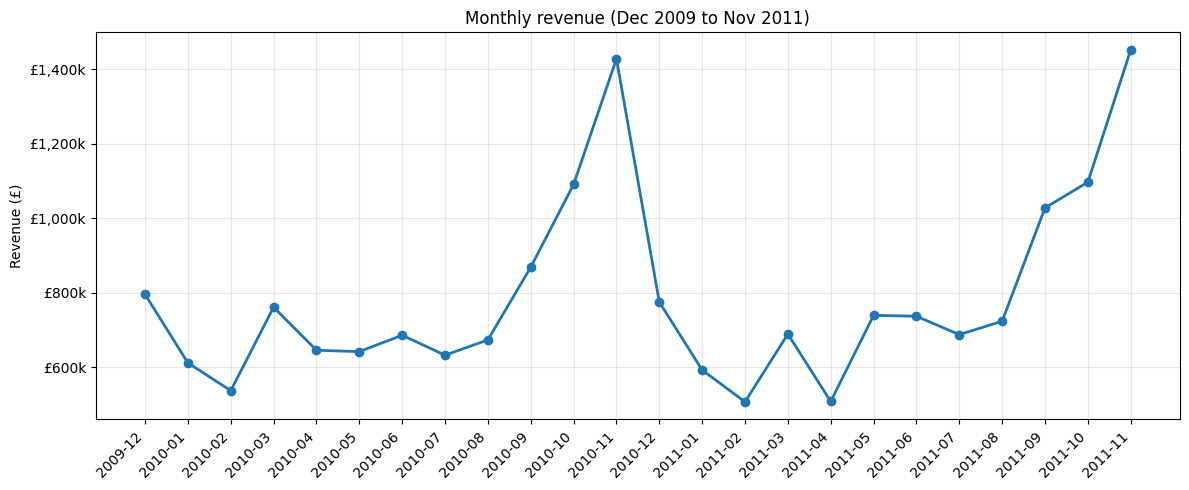

In [40]:
from matplotlib.ticker import FuncFormatter

monthly = sales.groupby("YearMonth")["Revenue"].sum()
monthly = monthly[monthly.index < pd.Period("2011-12")]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index.astype(str), monthly.values, marker="o", linewidth=2)
ax.set_title("Monthly revenue (Dec 2009 to Nov 2011)")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.grid(alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observations: monthly revenue**
- Revenue follows a strong seasonal pattern. It is flat at roughly £500k to £800k a month from January to August, then climbs from September to a peak in November.
- November is the biggest month in both years: about £1.43M in 2010 and about £1.45M in 2011, roughly double a typical spring or summer month.
- December 2010 drops sharply to about £775k. The data stops on 9 December 2011, so December is excluded from this chart.
- The lowest months are February and April 2011, at about £505k to £510k.
- The Sept to Nov build-up repeats each year, so a forecasting model must learn this seasonality.

### 12.3 Seasonality: 2010 vs 2011
Plotting the same months of each year on one chart shows whether the seasonal pattern repeats, and whether 2011 is growing against 2010.

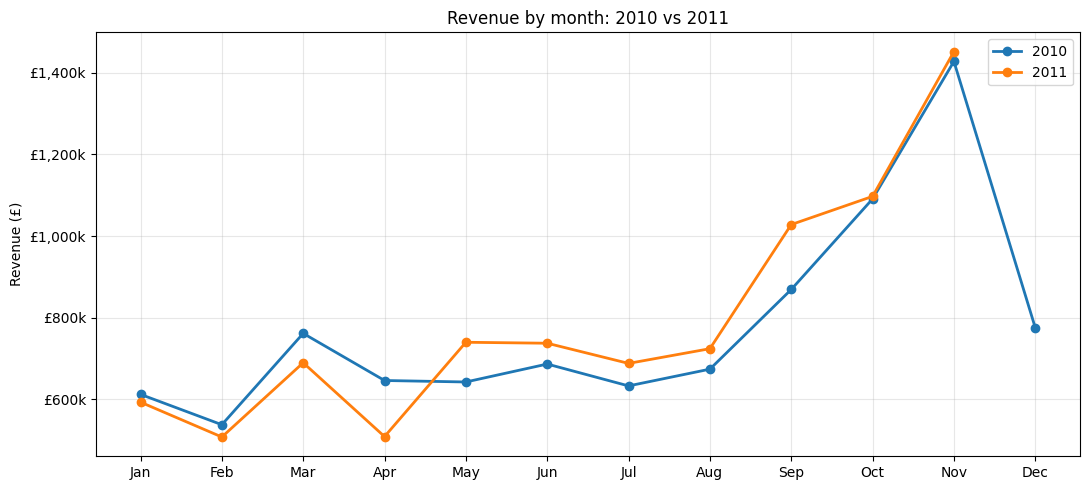

In [41]:
full = sales[sales["YearMonth"] < pd.Period("2011-12")]
season = full.pivot_table(index="Month", columns="Year", values="Revenue", aggfunc="sum")[[2010, 2011]]
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(11, 5))
for yr in [2010, 2011]:
    ax.plot(season.index, season[yr], marker="o", linewidth=2, label=str(yr))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_title("Revenue by month: 2010 vs 2011")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observations: 2010 vs 2011**
- The seasonal shape repeats: a flat first half, a climb from September, a peak in November and a sharp fall in December 2010 to about £775k.
- 2011 was below 2010 from January to April, with April the weakest gap (about £510k against £645k).
- From May to November 2011 was above 2010 in every month. The biggest gain is September, about £1.03M against £870k.
- October and November are almost identical in both years (November £1.45M against £1.43M), so the peak itself did not grow much. The growth came from a stronger build-up to it.

### 12.4 Orders and average order value
Revenue is orders multiplied by the average spend per order. Splitting them shows whether growth comes from more orders or bigger baskets.

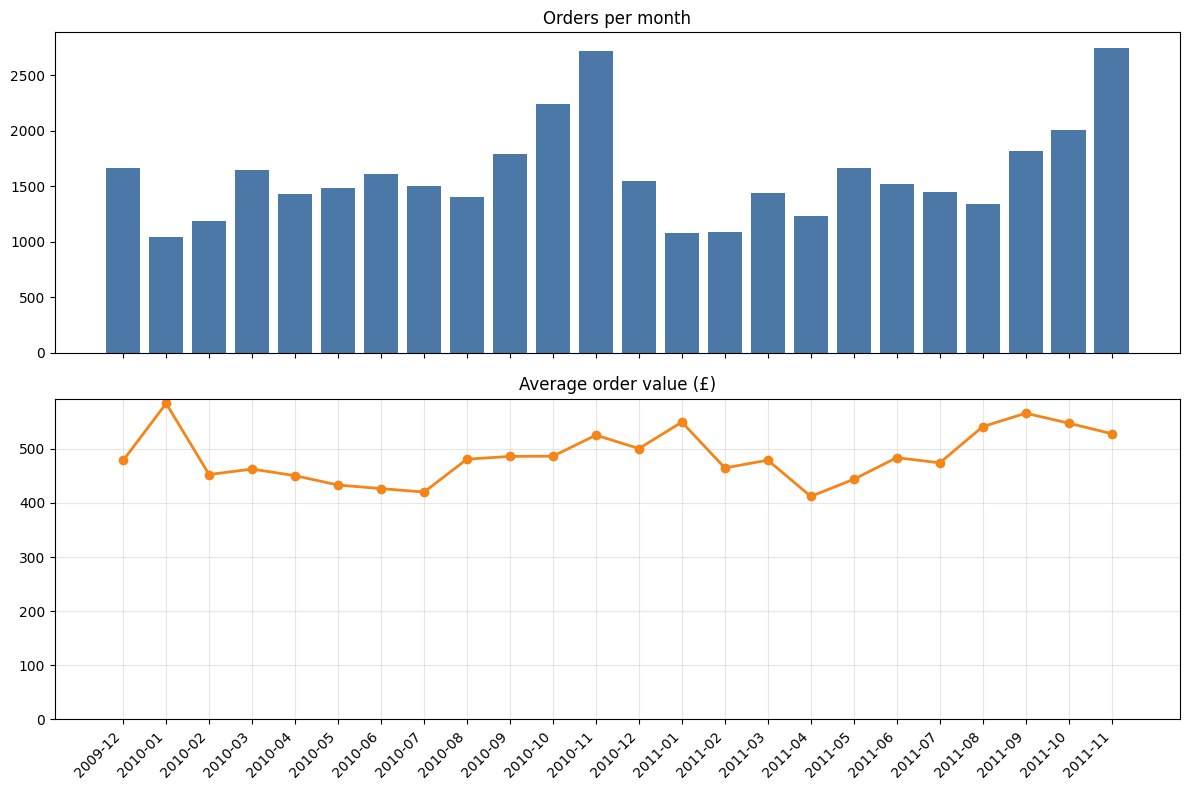

,Revenue,Orders,AOV
YearMonth,,,
2011-11,"1,452,112.69",2751,527.85
2010-11,"1,428,107.71",2719,525.23
2011-10,"1,097,379.60",2005,547.32


In [42]:
m = full.groupby("YearMonth").agg(Revenue=("Revenue", "sum"), Orders=("Invoice", "nunique"))
m["AOV"] = m["Revenue"] / m["Orders"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.bar(m.index.astype(str), m["Orders"], color="#4c78a8")
ax1.set_title("Orders per month")
ax2.plot(m.index.astype(str), m["AOV"], marker="o", linewidth=2, color="#f58518")
ax2.set_title("Average order value (£)")
ax2.set_ylim(0, None)
ax2.grid(alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

m.sort_values("Revenue", ascending=False).head(3)

**Observations: orders and average order value**
- The three highest-revenue months are Nov 2011 (£1.45M, 2,751 orders), Nov 2010 (£1.43M, 2,719 orders) and Oct 2011 (£1.10M, 2,005 orders).
- Order volume drives the seasonal peak. Orders rise from about 1,400 to 1,500 a month in summer to more than 2,700 in November, an increase of roughly 80%. They then fall back to about 1,500 in December and about 1,080 in January.
- Average order value moves much less. It rises from about £420 to £480 in mid-year to £525 to £570 in autumn, an increase of roughly 25%. Higher AOV adds to the peak, but order count explains most of it.
- AOV ranges from about £410 (April 2011) to about £585 (January 2010). January 2010 combines low order volume (about 1,040 orders) with a high AOV, which suggests a few large trade orders in a quiet month.
- Orders in November 2011 (2,751) are almost the same as in November 2010 (2,719), so the peak-season order count did not grow year on year.

### 12.5 Top products
Ranking products by revenue and by units shows which items carry the business. They are not always the same products.

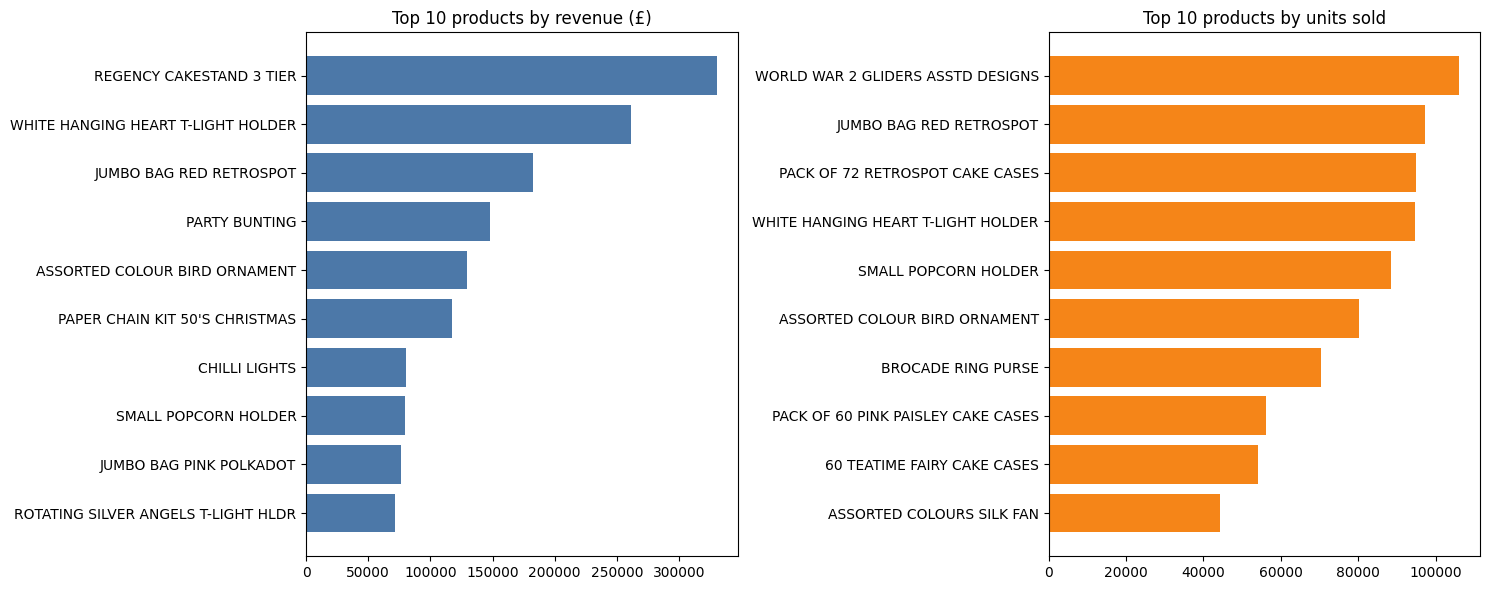

In [43]:
names = sales.groupby("StockCode")["Description"].agg(lambda s: s.mode().iloc[0])
prod  = sales.groupby("StockCode").agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum"))
prod["Name"] = names

top_rev   = prod.nlargest(10, "Revenue")
top_units = prod.nlargest(10, "Units")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top_rev["Name"].str[:36][::-1], top_rev["Revenue"][::-1], color="#4c78a8")
axes[0].set_title("Top 10 products by revenue (£)")
axes[1].barh(top_units["Name"].str[:36][::-1], top_units["Units"][::-1], color="#f58518")
axes[1].set_title("Top 10 products by units sold")
plt.tight_layout()
plt.show()

**Observations: top products**
- The top product by revenue is the Regency Cakestand 3 Tier (about £330k), followed by the White Hanging Heart T-Light Holder (about £260k) and the Jumbo Bag Red Retrospot (about £180k).
- The top product by units is the World War 2 Gliders (about 106k units), which is not in the top 10 by revenue. Likely a low-priced item, it sells in volume but earns little per unit.
- The Regency Cakestand tops revenue but is not in the top 10 by units, so it earns more per unit sold.
- Four products appear in both lists: White Hanging Heart T-Light Holder, Jumbo Bag Red Retrospot, Assorted Colour Bird Ornament and Small Popcorn Holder. These are the core products the business depends on.
- Ranking by units and by revenue gives different answers, so product reports should show both, as well as margin once cost data is available.

### 12.6 Revenue by country
The UK dominates, so we report its share and then chart the other countries separately. Otherwise they would all be tiny bars.

UK share of revenue: 85.3% | countries with sales: 43


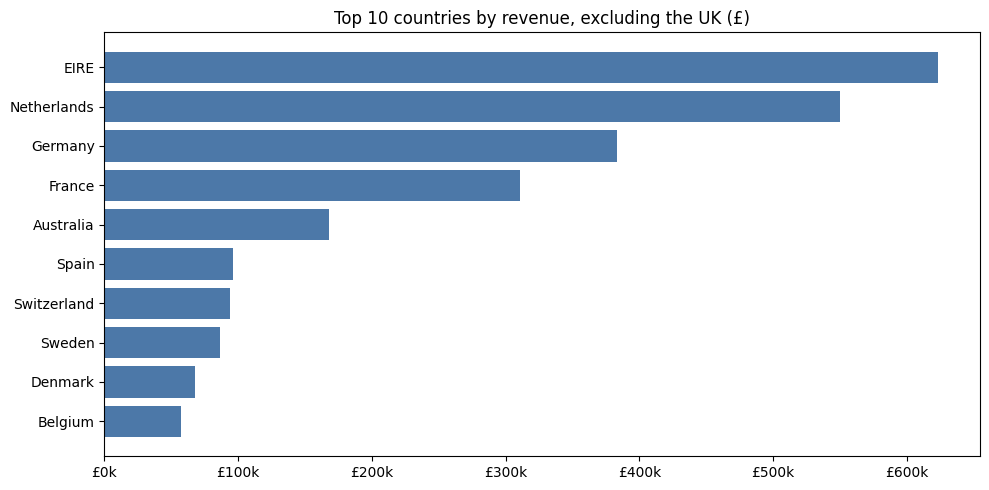

In [44]:
country  = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country["United Kingdom"] / country.sum()
print(f"UK share of revenue: {uk_share:.1%} | countries with sales: {len(country)}")

top_c = country.drop("United Kingdom").head(10)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_c.index[::-1], top_c.values[::-1], color="#4c78a8")
ax.set_title("Top 10 countries by revenue, excluding the UK (£)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
plt.tight_layout()
plt.show()

**Observations: revenue by country**
- The UK generates 85.3% of revenue. The data covers 43 countries, but international sales are only about 15% of the total.
- Among other countries, EIRE (about £620k) and the Netherlands (about £550k) are the largest, followed by Germany (about £380k), France (about £310k) and Australia (about £170k).
- These top four export markets account for roughly two thirds of all non-UK revenue, so exports depend on a few countries.
- Revenue per country is shown, not profit, and it doesn't account for shipping or customs costs.

### 12.7 Sales by day of week and hour
Knowing when customers buy helps with staffing, promotions and the timing of automated reports.

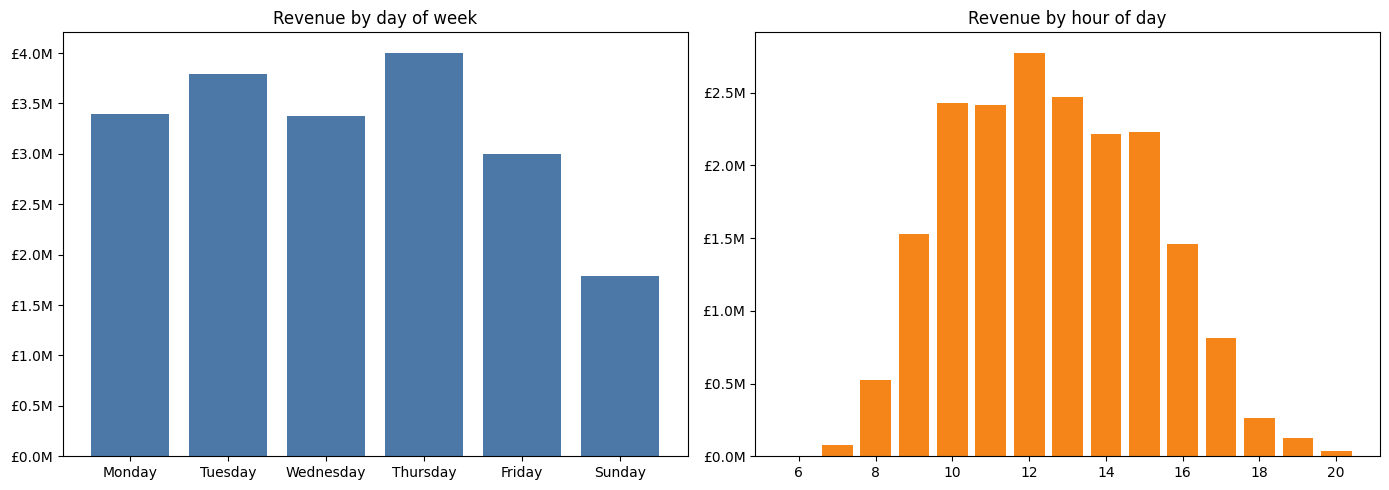

In [45]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
by_day  = sales.groupby("DayName")["Revenue"].sum().reindex(day_order)
by_hour = sales.groupby("Hour")["Revenue"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(by_day.index, by_day.values, color="#4c78a8")
axes[0].set_title("Revenue by day of week")
axes[1].bar(by_hour.index, by_hour.values, color="#f58518")
axes[1].set_title("Revenue by hour of day")
for ax in axes:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1e6:,.1f}M"))
plt.tight_layout()
plt.show()

**Observations: when customers buy**
- Thursday (about £4.0M) and Tuesday (about £3.8M) are the strongest days. Monday and Wednesday are close behind at about £3.4M, Friday is lower at about £3.0M, and Sunday is the weakest at about £1.8M.
- There are no Saturday sales in the data.
- Revenue peaks at 12:00 (about £2.8M), and every hour from 10:00 to 15:00 is above £2.2M. Very little is sold before 8:00 or after 18:00.
- This is a weekday, working-hours pattern, which fits trade customers placing orders during the business day.

### 12.8 Order size distribution
The average order value hides how orders are spread. A histogram shows whether most orders are small with a few very large ones.

count   39,510.00
mean       490.20
std      1,122.62
min          0.19
25%        150.32
50%        301.20
75%        484.14
max     52,940.94
Name: Revenue, dtype: float64


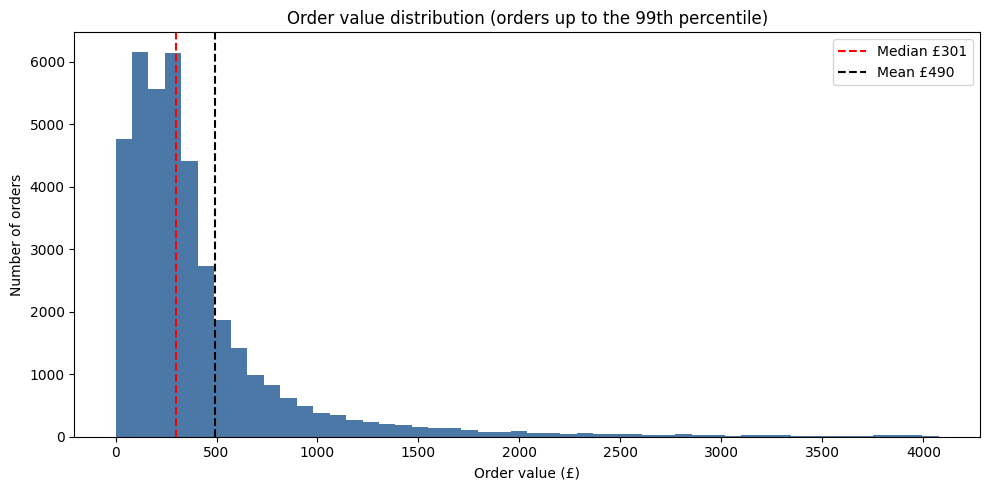

In [46]:
order_val = sales.groupby("Invoice")["Revenue"].sum()
print(order_val.describe())

cap = order_val.quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(order_val[order_val <= cap], bins=50, color="#4c78a8")
ax.axvline(order_val.median(), color="red", linestyle="--", label=f"Median £{order_val.median():,.0f}")
ax.axvline(order_val.mean(), color="black", linestyle="--", label=f"Mean £{order_val.mean():,.0f}")
ax.set_title("Order value distribution (orders up to the 99th percentile)")
ax.set_xlabel("Order value (£)")
ax.set_ylabel("Number of orders")
ax.legend()
plt.tight_layout()
plt.show()

**Observations: order size**
- The median order is £301 but the mean is £490. A few very large orders pull the average well above the typical order, so the median describes a normal order better.
- Half of all orders are between £150 and £484 (the 25% to 75% range), but the largest order is £52,941.
- The chart stops at the 99th percentile (about £4,000), so the 1% of largest orders are not shown. The distribution has a long right tail.
- Any model or KPI built on order value should use the median, or cap or log-transform the extreme orders.

### 12.9 Customer concentration (Pareto)
Many businesses earn most of their revenue from a small share of customers. Here we measure how concentrated this one is. Only rows with a Customer ID are included.

Top 20% of customers generate 76.8% of identified revenue (5,852 customers)


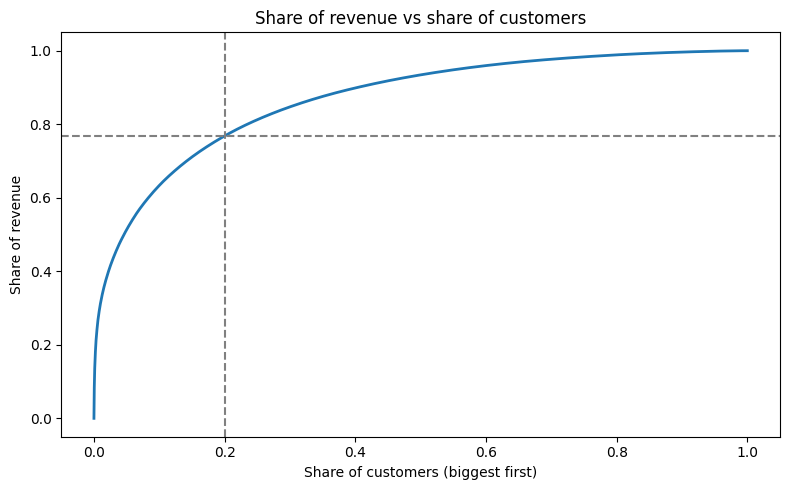

In [47]:
cust = (sales.dropna(subset=["CustomerID"])
             .groupby("CustomerID")["Revenue"].sum()
             .sort_values(ascending=False))
cum = cust.cumsum() / cust.sum()
x   = np.arange(1, len(cust) + 1) / len(cust)

top20 = cum.iloc[int(len(cust) * 0.2) - 1]
print(f"Top 20% of customers generate {top20:.1%} of identified revenue ({len(cust):,} customers)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.insert(x, 0, 0), np.insert(cum.values, 0, 0), linewidth=2)
ax.axvline(0.2, color="grey", linestyle="--")
ax.axhline(top20, color="grey", linestyle="--")
ax.set_title("Share of revenue vs share of customers")
ax.set_xlabel("Share of customers (biggest first)")
ax.set_ylabel("Share of revenue")
plt.tight_layout()
plt.show()

**Observations: customer concentration**
- The top 20% of identified customers generate 76.8% of identified revenue. This is close to the classic 80/20 pattern.
- The curve rises very steeply at the start, so a small group of the biggest customers carries a large share of sales.
- Losing a handful of top customers would hurt revenue much more than losing many small ones. This is the reason to build customer segmentation (RFM) and churn prediction in the next stage.
- This only covers rows with a Customer ID, so it describes the identified sales (about 77% of rows).

### 12.10 Returns rate by month
Returned value as a share of monthly sales shows whether returns are stable or spiking.

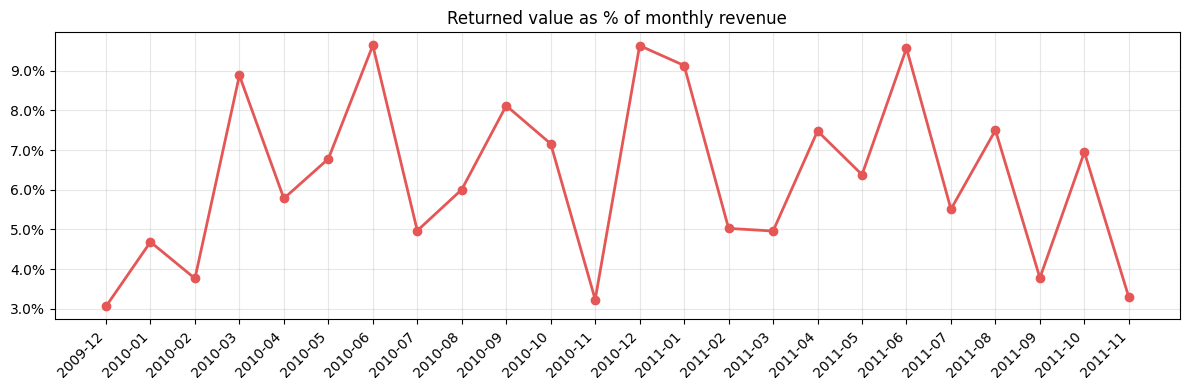

In [48]:
from matplotlib.ticker import PercentFormatter

ret_m = -returns.groupby("YearMonth")["Revenue"].sum()
rate  = (ret_m / monthly).dropna()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rate.index.astype(str), rate.values, marker="o", linewidth=2, color="#e45756")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_title("Returned value as % of monthly revenue")
ax.grid(alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observations: returns**
- The monthly return rate swings between about 3% and 9.6% with no steady trend, and the overall rate is 6.1%.
- It spikes in March 2010, June 2010, December 2010, January 2011 and June 2011, reaching 9% to 9.6%.
- It drops to its lowest in November of both years (about 3.2% and 3.3%). Returns usually arrive after the sale, so a very large sales month dilutes the rate, and the return spike shows up in December and January.
- Returns are dated by return month, not by the month of the original sale, so this chart shows return timing, not the return behaviour of each month's buyers.

## 13. Key findings
1. **Seasonality is the dominant pattern.** Revenue doubles from summer to November, driven mainly by order volume. A forecasting model must capture this yearly cycle.
2. **Growth is modest.** November 2011 was only 1.7% above November 2010.
3. **Customers are concentrated.** The top 20% of customers produce 76.8% of identified revenue.
4. **Orders are small to medium with a long tail.** The median order is £301 and the mean is £490, so extreme orders must be handled with care.
5. **Returns are volatile at 6.1% of sales.** Spikes follow peak months and are worth monitoring.
6. **Data quality needed real work.** 5.9% of rows were removed or set aside, including £274,971.60 of orders cancelled on the same day, which would have overstated revenue.
7. **Next steps:** customer segmentation (RFM) and churn, then sales forecasting, anomaly detection and automated insight generation.
8. **Top products differ by revenue and by units.** The Regency Cakestand leads revenue and the World War 2 Gliders lead units, so reporting should show both.
9. **The business is UK-centred.** The UK is 85.3% of revenue, and four countries (EIRE, Netherlands, Germany, France) make up most of the rest.

## 14. Customer segmentation (RFM)
RFM scores each customer on three questions: how recently they bought (Recency), how often (Frequency) and how much they spent (Monetary). Grouping customers by these scores shows who to protect, who to win back and who is lost. Only customers with a Customer ID are included.

In [49]:
snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

g = sales.dropna(subset=["CustomerID"]).groupby("CustomerID")
rfm = pd.DataFrame({
    "Recency":   (snapshot - g["InvoiceDate"].max()).dt.days,
    "Frequency": g["Invoice"].nunique(),
    "Monetary":  g["Revenue"].sum(),
})
rfm.describe()

,Recency,Frequency,Monetary
count,"5,852.00","5,852.00","5,852.00"
mean,199.80,6.25,"2,869.72"
std,208.54,12.75,"14,083.08"
min,0.00,1.00,2.90
25%,25.00,1.00,339.24
50%,95.00,3.00,855.58
75%,379.00,7.00,"2,237.29"
max,738.00,373.00,"580,987.04"


In [50]:
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

conditions = [
    (rfm["R"] >= 4) & (rfm["F"] >= 4),
    (rfm["R"] >= 3) & (rfm["F"] >= 3),
    (rfm["R"] >= 4) & (rfm["F"] <= 2),
    (rfm["R"] <= 2) & (rfm["F"] >= 3),
    (rfm["R"] <= 2) & (rfm["F"] <= 2),
]
names = ["Champions", "Loyal", "New / Promising", "At risk", "Hibernating"]
rfm["Segment"] = np.select(conditions, names, default="Needs attention")

seg = (rfm.groupby("Segment")
          .agg(Customers=("Monetary", "size"), Revenue=("Monetary", "sum"), AvgRecency=("Recency", "mean"))
          .sort_values("Revenue", ascending=False))
seg["Revenue share"] = (seg["Revenue"] / seg["Revenue"].sum()).map("{:.1%}".format)
seg

,Customers,Revenue,AvgRecency,Revenue share
Segment,,,,
Champions,1469,"11,780,088.81",19.69,70.1%
Loyal,1214,"2,442,959.31",77.55,14.5%
At risk,828,"1,499,134.15",366.96,8.9%
Hibernating,1512,"622,934.75",456.24,3.7%
New / Promising,447,"243,417.12",27.53,1.4%
Needs attention,382,"205,062.23",105.24,1.2%


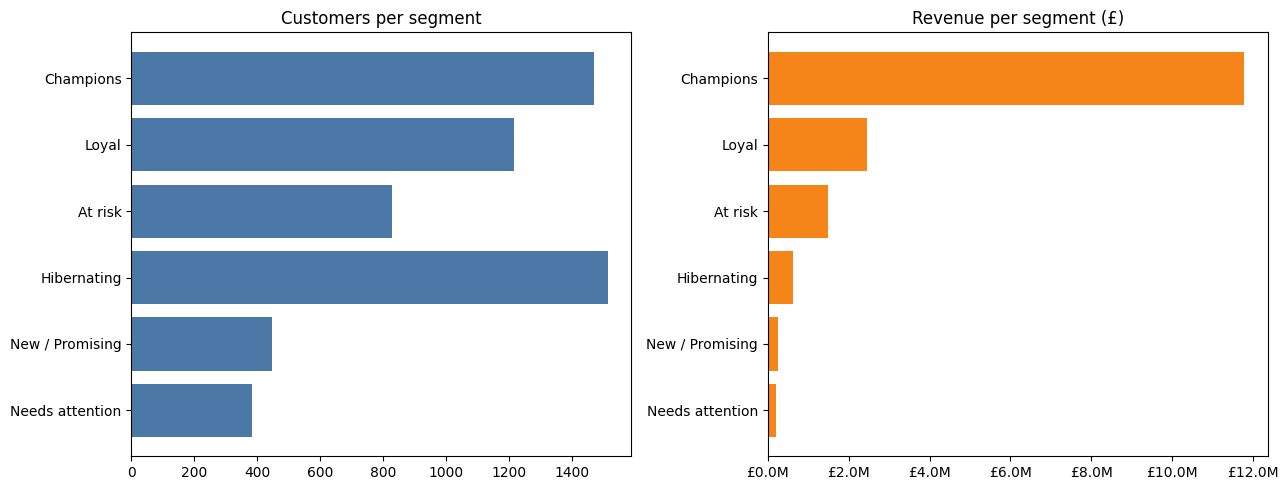

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(seg.index[::-1], seg["Customers"][::-1], color="#4c78a8")
axes[0].set_title("Customers per segment")
axes[1].barh(seg.index[::-1], seg["Revenue"][::-1], color="#f58518")
axes[1].set_title("Revenue per segment (£)")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1e6:,.1f}M"))
plt.tight_layout()
plt.show()

**Observations: customer segments**
- The 5,852 identified customers split into six segments. Hibernating is the biggest by headcount (about 1,500 customers) and Champions is next (about 1,470), followed by Loyal (about 1,210), At risk (about 830), New / Promising (about 450) and Needs attention (about 380).
- Revenue is far more concentrated than headcount. Champions are about 25% of customers but generate about £11.7M, roughly 70% of identified revenue. Loyal customers add about £2.4M and At risk customers about £1.4M.
- Hibernating customers are the largest group by count but contribute only about £0.6M. Most of them bought rarely and long ago, so winning them back has a low return per customer.
- The At risk segment (about 830 customers, about £1.4M) is the most valuable group to act on. They bought often in the past but not recently, so a retention campaign here protects real revenue.
- New / Promising customers are few (about 450) and small in revenue so far. Getting a second purchase from them is the cheapest way to grow the Loyal segment.
- These segments come from rule-based scores. The next step builds a churn model to predict individual customers' risk, instead of relying on rules alone.

## 15. Churn prediction
A customer is labelled churned if they bought before 9 June 2011 but made no purchase in the following six months (to the end of the data). Features are built only from the period before the cutoff, so the model never sees the future it is trying to predict.

In [52]:
cutoff = pd.Timestamp("2011-06-09")

known  = sales.dropna(subset=["CustomerID"])
past   = known[known["InvoiceDate"] < cutoff]
future = known[known["InvoiceDate"] >= cutoff]
past_returns = returns[returns["InvoiceDate"] < cutoff]

gp = past.groupby("CustomerID")
feat = pd.DataFrame({
    "Recency":       (cutoff - gp["InvoiceDate"].max()).dt.days,
    "Tenure":        (cutoff - gp["InvoiceDate"].min()).dt.days,
    "Frequency":     gp["Invoice"].nunique(),
    "Monetary":      gp["Revenue"].sum(),
    "Products":      gp["StockCode"].nunique(),
    "Items":         gp["Quantity"].sum(),
})
feat["AvgOrderValue"]  = feat["Monetary"] / feat["Frequency"]
feat["OrdersPerMonth"] = feat["Frequency"] / (feat["Tenure"] / 30 + 1)
feat["ReturnValue"]    = (-past_returns.groupby("CustomerID")["Revenue"].sum()).reindex(feat.index).fillna(0)

feat["Churned"] = (~feat.index.isin(future["CustomerID"].unique())).astype(int)
feat = feat.astype(float)

print(f"Customers: {len(feat):,} | churn rate: {feat['Churned'].mean():.1%}")
feat.head()

Customers: 4,941 | churn rate: 47.9%


,Recency,Tenure,Frequency,Monetary,Products,Items,AvgOrderValue,OrdersPerMonth,ReturnValue,Churned
CustomerID,,,,,,,,,,
12346,345.00,463.00,2.00,169.36,24.00,24.00,84.68,0.12,424.60,1.00
12347,62.00,220.00,4.00,"2,434.96",90.00,"1,626.00",608.74,0.48,0.00,0.00
12348,64.00,254.00,4.00,"1,388.40",24.00,"2,488.00",347.10,0.42,0.00,0.00
12349,223.00,405.00,2.00,"2,221.14",89.00,991.00,"1,110.57",0.14,24.15,0.00
12350,126.00,126.00,1.00,294.40,16.00,196.00,294.40,0.19,0.00,1.00


**Observations: churn setup**
- 4,941 customers bought before the 9 June 2011 cutoff. Of these, 47.9% made no purchase in the following six months, so they are labelled churned.
- The two classes are close to balanced (644 retained vs 592 churned in the test set), so accuracy is a fair measure alongside ROC-AUC.
- A churn rate near 48% is high but plausible for this business. Many customers buy once or twice and never return, which matches the large Hibernating segment seen in the RFM analysis.

### 15.1 Train and compare models
We train a simple model (logistic regression) and a stronger one (random forest) and compare them on customers the model has never seen.

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report

X = feat.drop(columns="Churned")
y = feat["Churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    print(f"{name}: ROC-AUC = {roc_auc_score(y_test, p):.3f}")

best = models["Random Forest"]
print()
print(classification_report(y_test, best.predict(X_test), target_names=["Retained", "Churned"]))

Logistic Regression: ROC-AUC = 0.800
Random Forest: ROC-AUC = 0.801

              precision    recall  f1-score   support

    Retained       0.75      0.71      0.73       644
     Churned       0.70      0.75      0.73       592

    accuracy                           0.73      1236
   macro avg       0.73      0.73      0.73      1236
weighted avg       0.73      0.73      0.73      1236



**Observations: model performance**
- Both models score a ROC-AUC of about 0.80 (logistic regression 0.800, random forest 0.801). Given a churner and a retained customer, the model ranks the churner as riskier about 80% of the time. For behavioural data with only purchase history, this is a solid result.
- At the default threshold the model is 73% accurate. For churned customers, precision is 0.70 (of customers flagged as churners, 70% really churned) and recall is 0.75 (it catches 75% of those who actually churned).
- The simple logistic regression performs as well as the random forest. This suggests the churn signal is mostly simple and roughly linear, so the transparent model is just as defensible for business use.
- The test set (1,236 customers) was never seen during training, so these numbers describe performance on new customers, not on memorised ones.

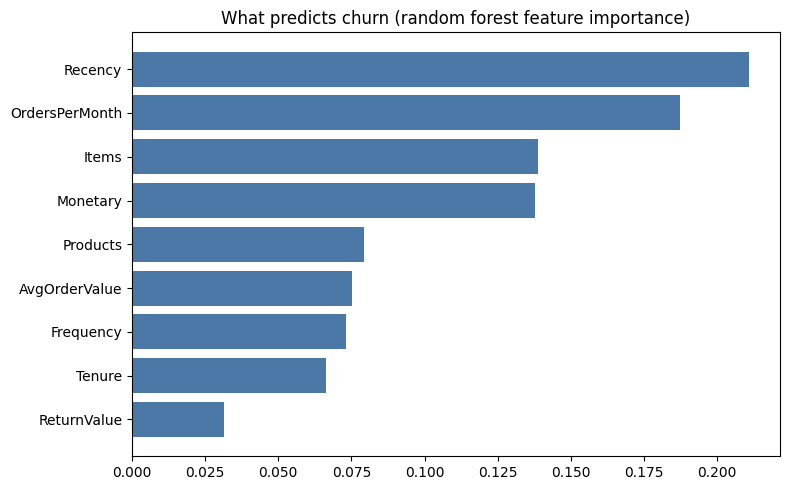

In [54]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color="#4c78a8")
ax.set_title("What predicts churn (random forest feature importance)")
plt.tight_layout()
plt.show()

**Observations: what drives churn**
- Recency is the strongest predictor, followed by orders per month. Customers who have been quiet for longer, and who buy less often, are the most likely to be gone six months later.
- Items bought and total spend come next. Volume and value of past purchasing matter more than how many different products a customer tried or how long they have been a customer (tenure).
- Return value is the weakest predictor, so returning goods is not a strong sign of leaving.
- Feature importance shows which variables matter, not in which direction. We know from the business logic that higher recency (more days since the last purchase) means higher churn risk.
- Practical meaning: a simple "days since last order" alert already captures much of the risk, and the model adds the rest.

### 15.2 Current churn risk for every customer
We retrain on all labelled customers, rebuild the same features as of the end of the data, and score every customer. This produces a risk score and a priority list of valuable customers likely to leave.

In [55]:
def build_features(cut):
    p   = known[known["InvoiceDate"] < cut]
    pr  = returns[returns["InvoiceDate"] < cut]
    gp  = p.groupby("CustomerID")
    f = pd.DataFrame({
        "Recency":   (cut - gp["InvoiceDate"].max()).dt.days,
        "Tenure":    (cut - gp["InvoiceDate"].min()).dt.days,
        "Frequency": gp["Invoice"].nunique(),
        "Monetary":  gp["Revenue"].sum(),
        "Products":  gp["StockCode"].nunique(),
        "Items":     gp["Quantity"].sum(),
    })
    f["AvgOrderValue"]  = f["Monetary"] / f["Frequency"]
    f["OrdersPerMonth"] = f["Frequency"] / (f["Tenure"] / 30 + 1)
    f["ReturnValue"]    = (-pr.groupby("CustomerID")["Revenue"].sum()).reindex(f.index).fillna(0)
    return f.astype(float)

final_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                     random_state=42, n_jobs=-1).fit(X, y)

now = build_features(snapshot)
now["ChurnRisk"] = final_model.predict_proba(now[X.columns])[:, 1]
now["RiskBand"]  = pd.cut(now["ChurnRisk"], [0, 0.4, 0.7, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)
now = now.join(rfm["Segment"])

print(now["RiskBand"].value_counts().to_string())
pd.crosstab(now["Segment"], now["RiskBand"])

RiskBand
Low       2308
High      1816
Medium    1728


RiskBand,Low,Medium,High
Segment,,,
At risk,17,428,383
Champions,1390,79,0
Hibernating,4,224,1284
Loyal,661,544,9
Needs attention,24,249,109
New / Promising,212,204,31


**Observations: current churn risk**
- Of 5,852 customers, 1,816 (31%) are rated High risk, 1,728 (30%) Medium and 2,308 (39%) Low.
- The model agrees with the RFM segments. No Champion is rated High risk and 1,390 of 1,469 are Low. At the other end, 1,284 of 1,512 Hibernating customers are High risk.
- The At risk segment is split: 383 customers are High risk and 428 are Medium. The Medium group is the best target for retention offers because they have gone quiet recently, not long ago.
- Loyal customers are mostly Low (661) or Medium (544) risk. A drop in order frequency among them is an early warning to watch.

In [56]:
priority = (now[now["RiskBand"] == "High"]
            .sort_values("Monetary", ascending=False)
            .head(15)[["Segment", "Recency", "Frequency", "Monetary", "ChurnRisk"]])
priority["ChurnRisk"] = priority["ChurnRisk"].map("{:.0%}".format)
priority

,Segment,Recency,Frequency,Monetary,ChurnRisk
CustomerID,,,,,
16754,At risk,372.00,29.00,"62,838.95",79%
13093,At risk,275.00,55.00,"54,144.25",72%
17850,At risk,372.00,155.00,"51,208.87",81%
13902,At risk,632.00,5.00,"34,023.26",81%
12482,At risk,576.00,27.00,"21,941.72",80%
15808,At risk,306.00,21.00,"17,180.25",75%
13564,At risk,354.00,36.00,"15,880.22",81%
17448,At risk,529.00,41.00,"14,448.67",81%
18087,At risk,290.00,16.00,"13,908.72",71%


**Observations: priority customers**
- The list shows the 15 highest-spending customers rated High risk. Their lifetime spend ranges from about £9,400 to £62,800, and the top one (customer 16754) alone has spent £62,839 over 29 orders.
- Most are At risk customers with many past orders (up to 155) who have not bought for 9 to 22 months. Their churn risk is 71% to 91%.
- Important caveat: the model predicts no purchase in the next six months. These customers have already been silent for 264 to 686 days, so many may already be lost. A call or personal offer is still worthwhile given their value, but the expected recovery rate is lower than for customers who went quiet recently.
- Some entries are one-off large buyers (for example customers 13687 and 18052, one order each worth over £10k), whose value comes from a single purchase, not a buying pattern.
- Business use: this list turns the model into an action, a ranked call list for the sales team, ordered by value.

## 16. Sales forecasting
The goal is to forecast daily revenue 28 days ahead. Models are trained on data up to 10 November 2011 and tested on the final 28 days, which they have never seen. We compare simple baselines with Holt-Winters first, then a deep learning (LSTM) model.

738 days | train: 2009-12-01 to 2011-11-10 | test: 2011-11-11 to 2011-12-08


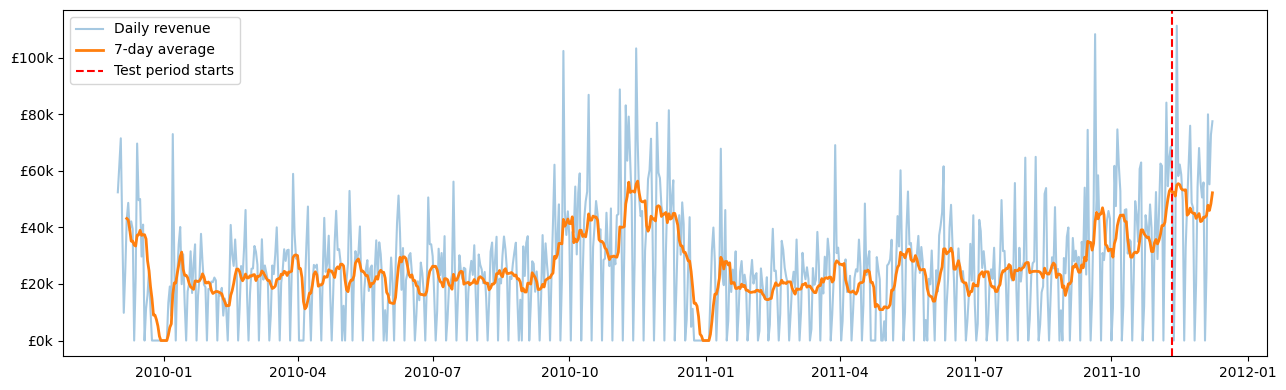

In [57]:
daily = sales.groupby("Date")["Revenue"].sum()
daily = daily[daily.index < "2011-12-09"]
daily = daily.asfreq("D", fill_value=0)

H = 28
train, test = daily.iloc[:-H], daily.iloc[-H:]
print(f"{len(daily)} days | train: {train.index[0].date()} to {train.index[-1].date()} | test: {test.index[0].date()} to {test.index[-1].date()}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, alpha=0.4, label="Daily revenue")
ax.plot(daily.index, daily.rolling(7).mean(), linewidth=2, label="7-day average")
ax.axvline(test.index[0], color="red", linestyle="--", label="Test period starts")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.legend()
plt.tight_layout()
plt.show()

**Observations: daily revenue series**
- The series covers 738 days (1 Dec 2009 to 8 Dec 2011). The 9 December partial day was excluded.
- Daily revenue is very noisy, from £0 to over £100k. The zero days are structural: there are no sales on Saturdays, and the shop was closed over the Christmas to New Year period.
- The 7-day average shows the same seasonal shape as the monthly view: low and flat for most of the year, then a climb from September to the peak in November, and a collapse in late December.
- The test period (11 Nov to 8 Dec 2011) sits in the peak season, which is the hardest part of the year to forecast.

In [58]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def scores(actual, pred):
    err = actual.values - np.asarray(pred)
    return {"MAE (£)": np.abs(err).mean(), "RMSE (£)": np.sqrt((err**2).mean()),
            "WAPE": np.abs(err).sum() / actual.sum()}

pred_last4 = train.iloc[-H:].values
pred_ly    = daily.shift(364).iloc[-H:].values

hw = ExponentialSmoothing(train, trend="add", damped_trend=True,
                          seasonal="add", seasonal_periods=7).fit()
pred_hw = hw.forecast(H).clip(lower=0).values

results = pd.DataFrame({
    "Repeat last 4 weeks":        scores(test, pred_last4),
    "Same weekday last year":     scores(test, pred_ly),
    "Holt-Winters (weekly)":      scores(test, pred_hw),
}).T
results["WAPE"] = results["WAPE"].map("{:.1%}".format)
results

,MAE (£),RMSE (£),WAPE
Repeat last 4 weeks,"13,056.70","19,381.67",27.0%
Same weekday last year,"10,303.60","13,883.14",21.3%
Holt-Winters (weekly),"12,396.64","16,044.82",25.6%


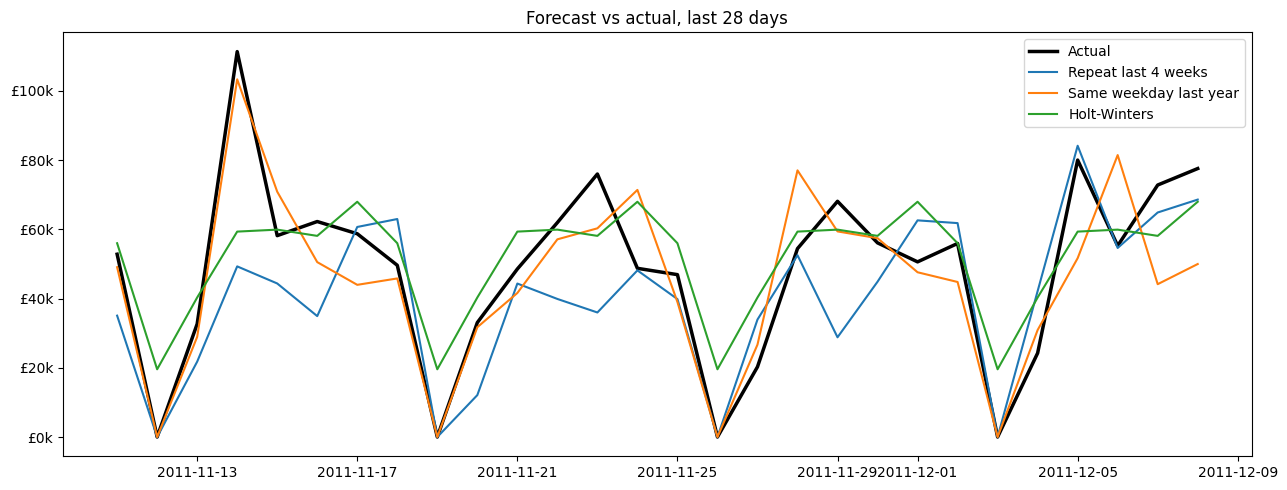

In [59]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test.index, test.values, color="black", linewidth=2.5, label="Actual")
ax.plot(test.index, pred_last4, label="Repeat last 4 weeks")
ax.plot(test.index, pred_ly, label="Same weekday last year")
ax.plot(test.index, pred_hw, label="Holt-Winters")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.set_title("Forecast vs actual, last 28 days")
ax.legend()
plt.tight_layout()
plt.show()

**Observations: baseline forecasts**
- On the last 28 days, "same weekday last year" is the best of the three: MAE £10,304 and WAPE 21.3%. Holt-Winters has an MAE of £12,397 (WAPE 25.6%) and repeating the last four weeks is the weakest at £13,057 (WAPE 27.0%).
- Last year's pattern wins because the peak-season climb repeats every year, and a model that only looks at recent weeks cannot see it coming.
- Holt-Winters learns the weekly rhythm but predicts a smooth, flat level. It misses the sharp spike on 14 November (about £111k) and also predicts sales on Saturdays, which never happen.
- All models follow the weekly cycle with zero sales on Saturdays, but none anticipates the largest spikes. Daily revenue is driven by a few very large orders, which no purely historical model can foresee.
- Any new model must beat 21.3% WAPE to justify its added complexity.

In [60]:
import keras
print(keras.__version__, keras.backend.backend())

3.13.2 tensorflow


### 16.1 LSTM forecast
The LSTM reads the previous 56 days (revenue plus calendar features) and predicts the next day. For the 28-day forecast it predicts one day, feeds the prediction back in, and repeats. Revenue is log-transformed and scaled using the training period only.

In [61]:
from keras import layers

W = 56
n_train = len(train)

logy = np.log1p(daily.values)
mu, sd = logy[:n_train].mean(), logy[:n_train].std()
y_s = (logy - mu) / sd

def calendar(dates):
    dow, doy = dates.dayofweek.values, dates.dayofyear.values
    return np.column_stack([np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7),
                            np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)])

all_dates = pd.date_range(daily.index[0], periods=len(daily) + 1, freq="D")
cal = calendar(all_dates)
F = np.column_stack([y_s, cal[1:]])

X_tr = np.array([F[i-W:i] for i in range(W, n_train)])
y_tr = np.array([y_s[i] for i in range(W, n_train)])
print("Training windows:", X_tr.shape, "| targets:", y_tr.shape)

Training windows: (654, 56, 5) | targets: (654,)


Stopped after 47 epochs | best validation loss: 0.107


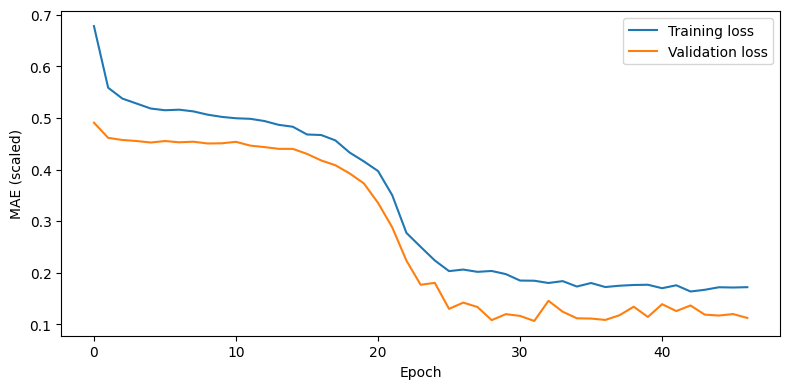

In [62]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(W, 5)),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1),
])
model.compile(optimizer="adam", loss="mae")

early_stop = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
history = model.fit(X_tr, y_tr, epochs=150, batch_size=32,
                    validation_split=0.15, callbacks=[early_stop], verbose=0)

print(f"Stopped after {len(history.history['loss'])} epochs | best validation loss: {min(history.history['val_loss']):.3f}")

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MAE (scaled)")
plt.legend(); plt.tight_layout(); plt.show()

**Observations: LSTM training**
- The model trained on 654 windows, each covering 56 days with 5 features per day.
- The loss falls steeply between epochs 20 and 25 and then flattens. Early stopping ended training at epoch 47, and the best validation loss was 0.107 (scaled units).
- There is no sign of overfitting: the validation loss does not rise while the training loss falls. The validation loss sits below the training loss because dropout is active only during training.
- Holt-Winters is penalised here because it also predicts sales on Saturdays. Once Saturdays are set to zero for every model (section 16.1), Holt-Winters improves to WAPE 19.8% and becomes the best of the single models on this window.

,MAE (£),RMSE (£),WAPE,28-day total error
Repeat last 4 weeks,"13,056.70","19,381.67",27.0%,-16.8%
Same weekday last year,"10,303.60","13,883.14",21.3%,-6.7%
Holt-Winters,"9,601.79","14,239.30",19.8%,0.8%
LSTM,"15,401.20","21,411.44",31.8%,-28.1%


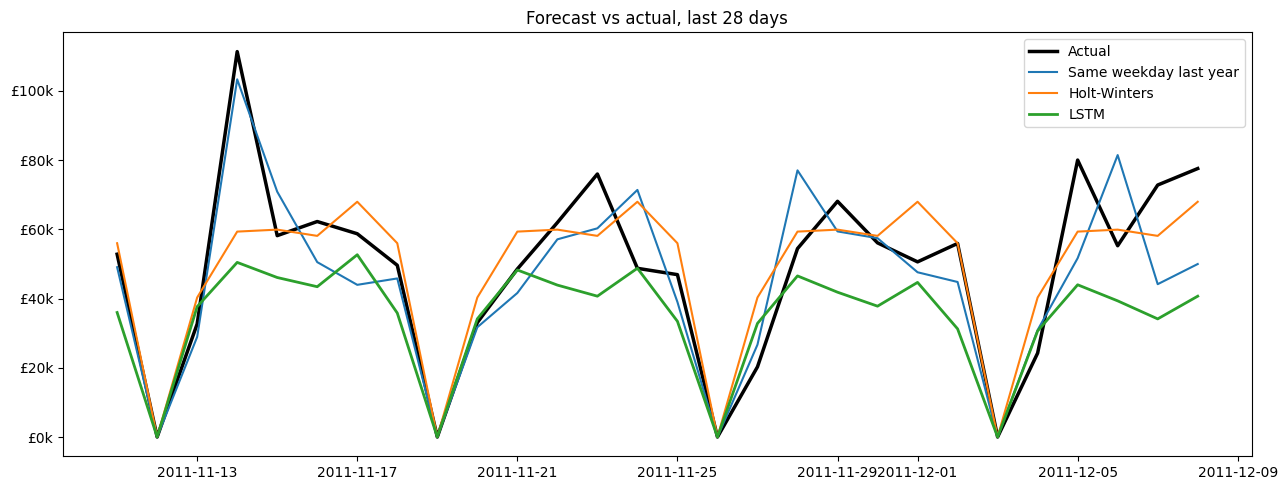

In [63]:
window = F[n_train - W:n_train].copy()
preds_s = []
for k in range(H):
    p = model.predict(window[None, :, :], verbose=0)[0, 0]
    preds_s.append(p)
    window = np.vstack([window[1:], np.concatenate([[p], cal[n_train + k + 1]])])

pred_lstm = np.expm1(np.array(preds_s) * sd + mu).clip(0)

closed = (test.index.dayofweek == 5)
pred_hw_f   = pred_hw.copy();   pred_hw_f[closed] = 0
pred_lstm_f = pred_lstm.copy(); pred_lstm_f[closed] = 0

def scores2(actual, pred):
    err = actual.values - np.asarray(pred)
    return {"MAE (£)": np.abs(err).mean(), "RMSE (£)": np.sqrt((err**2).mean()),
            "WAPE": np.abs(err).sum() / actual.sum(),
            "28-day total error": np.sum(pred) / actual.sum() - 1}

results2 = pd.DataFrame({
    "Repeat last 4 weeks":    scores2(test, pred_last4),
    "Same weekday last year": scores2(test, pred_ly),
    "Holt-Winters":           scores2(test, pred_hw_f),
    "LSTM":                   scores2(test, pred_lstm_f),
}).T
for c in ["WAPE", "28-day total error"]:
    results2[c] = results2[c].map("{:.1%}".format)
display(results2)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test.index, test.values, color="black", linewidth=2.5, label="Actual")
ax.plot(test.index, pred_ly, label="Same weekday last year")
ax.plot(test.index, pred_hw_f, label="Holt-Winters")
ax.plot(test.index, pred_lstm_f, label="LSTM", linewidth=2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.set_title("Forecast vs actual, last 28 days")
ax.legend(); plt.tight_layout(); plt.show()

**Observations: model comparison**
- With the "no Saturday sales" rule applied to every model, Holt-Winters is the most accurate on the last 28 days: MAE £9,602 and WAPE 19.8%. Same weekday last year follows (21.3%), then repeating the last four weeks (27.0%), and the LSTM is last (31.8%).
- Holt-Winters also has the best total for the month: its 28-day revenue total is only 0.8% off the actual figure. Same weekday last year is 6.7% low, repeating the last four weeks is 16.8% low and the LSTM is 28.1% low.
- The LSTM captures the weekly rhythm (zero on Saturdays, higher mid-week) but forecasts a flat level of about £40k to £50k and misses the peak-season level of £60k to £80k. It underestimates revenue by 28% over the month.
- Likely causes: with only two years of data, the network has seen just one peak season. It also forecasts recursively, so each prediction is built on earlier predictions and drifts toward the average, and it has no direct view of last year's level.
- Conclusion: a deep learning model is not automatically better. On this small dataset a well-tuned statistical model wins, so Holt-Winters is selected as the forecasting model for the app. The LSTM stays in the project as a tested alternative, and it will be used again for anomaly detection, where it suits the task better.
- Caveat: this is one 28-day window in the peak season, so a rolling backtest over several windows is used to confirm the choice.

### 16.2 Rolling backtest
One test window can be lucky. We repeat the forecast over eight consecutive 28-day windows (April to December 2011), refitting at each step, and compare the average error. We also test the average of Holt-Winters and last year's pattern.

In [64]:
rows = []
for k in range(8, 0, -1):
    end = len(daily) - k * H
    tr, te = daily.iloc[:end], daily.iloc[end:end + H]

    p_ly = daily.shift(364).iloc[end:end + H].values
    m = ExponentialSmoothing(tr, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7).fit()
    p_hw = m.forecast(H).clip(lower=0).values
    p_hw[te.index.dayofweek == 5] = 0
    p_avg = (p_ly + p_hw) / 2

    rows.append({"Window": f"{te.index[0].date()} to {te.index[-1].date()}",
                 "Last year": scores2(te, p_ly)["WAPE"],
                 "Holt-Winters": scores2(te, p_hw)["WAPE"],
                 "Average of both": scores2(te, p_avg)["WAPE"]})

bt = pd.DataFrame(rows).set_index("Window")
summary = bt.mean().to_frame("Average WAPE").T
display(bt.map("{:.1%}".format))
display(summary.map("{:.1%}".format))

,Last year,Holt-Winters,Average of both
Window,,,
2011-04-29 to 2011-05-26,33.5%,47.6%,35.2%
2011-05-27 to 2011-06-23,33.2%,36.1%,30.5%
2011-06-24 to 2011-07-21,37.4%,24.1%,28.7%
2011-07-22 to 2011-08-18,37.5%,39.5%,36.2%
2011-08-19 to 2011-09-15,34.0%,36.2%,33.4%
2011-09-16 to 2011-10-13,40.5%,29.0%,32.7%
2011-10-14 to 2011-11-10,25.4%,28.7%,22.4%
2011-11-11 to 2011-12-08,21.3%,19.8%,17.7%


,Last year,Holt-Winters,Average of both
Average WAPE,32.8%,32.6%,29.6%


**Observations: rolling backtest**
- Across eight consecutive 28-day windows (29 April to 8 December 2011), the average of Holt-Winters and last year's pattern has the lowest average error: WAPE 29.6%, against 32.6% for Holt-Winters alone and 32.8% for last year's pattern alone.
- No single model wins every window. The average is best in five of the eight windows, Holt-Winters is best in two (June to July and September to October) and last year's pattern in one (April to May).
- The average is never the worst model in any window, while Holt-Winters can be very poor (47.6% in the first window) and last year's pattern reaches 40.5% in September to October. Averaging two different models cuts the risk of a bad month.
- Accuracy depends on the season. Errors are about 30% to 40% in the quiet months and fall to 17.7% to 22.4% in the last two windows (mid-October to early December), when order volume is high and revenue is steadier.
- This is daily error. Daily revenue is dominated by a few very large orders, so day-level forecasts are naturally noisy. Totals over a week or a month are more reliable than individual days.
- Decision: the final forecasting model is the average of Holt-Winters (which learns the weekly pattern and recent level) and last year's same-weekday revenue (which carries the annual season, including the Christmas closure). The LSTM was tested but not selected because it underperformed on this small dataset.

### 16.3 Final forecast: the next 28 days
The selected model forecasts 28 days beyond the end of the data. The period includes the Christmas closure, so we first check from the data when the shop was closed in previous years.

In [65]:
zero_days = daily[(daily == 0) & (daily.index.dayofweek != 5)]
xmas = zero_days[(zero_days.index.month == 12) | (zero_days.index.month == 1)]
xmas.groupby(xmas.index.year).apply(lambda s: f"{s.index.min().date()} to {s.index.max().date()} ({len(s)} days)")

,Revenue
Date,
2009,2009-12-24 to 2009-12-31 (7 days)
2010,2010-01-01 to 2010-12-31 (9 days)
2011,2011-01-02 to 2011-01-03 (2 days)


**Observations: Christmas closure**
- The data shows a regular shutdown at the end of each year. Revenue is zero from 24 December until 2 or 3 January on weekdays and Sundays, apart from Saturdays, which are always empty. The output is grouped by calendar year, so December and January of the same winter appear in different rows.
- In winter 2009-10 the closed days run from 24 December 2009 into early January 2010, and in winter 2010-11 from 24 December 2010 to 3 January 2011.
- A forecasting model that ignores this would predict normal sales for a week and a half in which nothing is sold. This is why the final model carries last year's closed days into the forecast.

### 16.4 Same-period revenue in earlier years
Before judging the forecast, we compare the revenue from 9 December to 5 January in the two previous years.

Growth factor (last 56 days vs a year earlier): 1.05
Forecast total for the next 28 days: £478,170


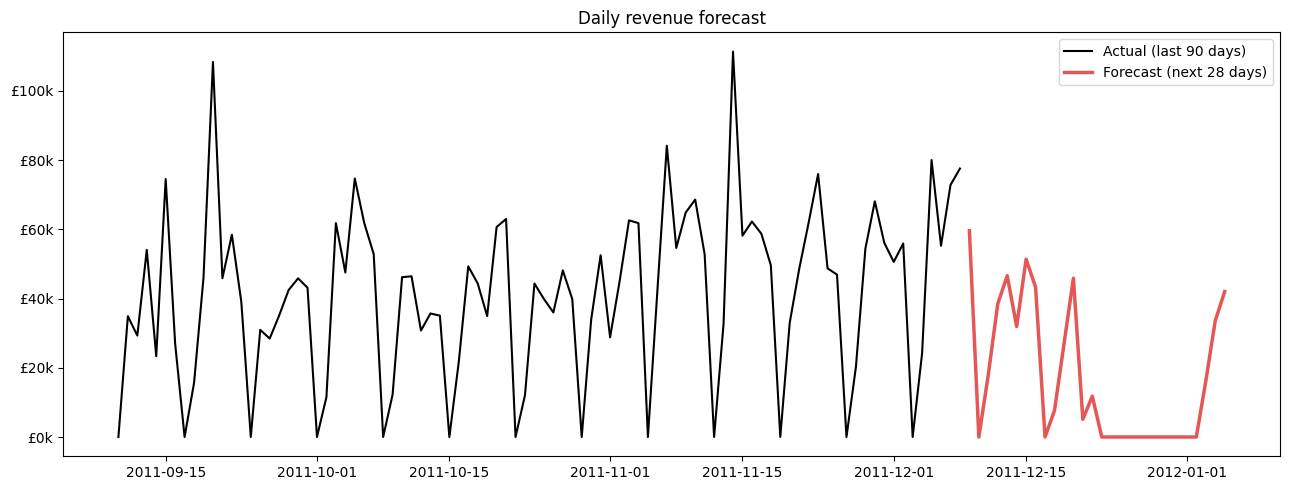

,Date,Forecast,HoltWinters,LastYear
0,2011-12-09,"59,599.00","57,711.00","56,685.62"
1,2011-12-10,0.00,0.00,0.00
2,2011-12-11,"18,006.00","38,796.00","17,125.65"
3,2011-12-12,"38,454.00","69,365.00","36,574.67"
4,2011-12-13,"46,605.00","62,792.00","44,327.11"
5,2011-12-14,"31,928.00","64,146.00","30,367.56"
6,2011-12-15,"51,380.00","65,553.00","48,868.14"
7,2011-12-16,"43,305.00","57,711.00","41,188.15"
8,2011-12-17,0.00,0.00,0.00
9,2011-12-18,"7,663.00","38,796.00","7,288.47"


In [78]:
future_idx = pd.date_range(daily.index[-1] + pd.Timedelta(days=1), periods=H, freq="D")

hw_full = ExponentialSmoothing(daily, trend="add", damped_trend=True,
                               seasonal="add", seasonal_periods=7).fit()
f_hw = hw_full.forecast(H).clip(lower=0).values
f_ly = daily.reindex(future_idx - pd.Timedelta(days=364)).values

g56 = daily.iloc[-56:].sum() / daily.shift(364).iloc[-56:].sum()
f_hw[future_idx.dayofweek == 5] = 0
f_final = f_ly * g56
f_final[future_idx.dayofweek == 5] = 0
f_final[f_ly == 0] = 0
print(f"Growth factor (last 56 days vs a year earlier): {g56:.2f}")

forecast = pd.DataFrame({"Date": future_idx, "Forecast": f_final.round(0),
                         "HoltWinters": f_hw.round(0), "LastYear": f_ly})
print(f"Forecast total for the next {H} days: £{f_final.sum():,.0f}")

recent = daily.iloc[-90:]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(recent.index, recent.values, color="black", label="Actual (last 90 days)")
ax.plot(future_idx, f_final, color="#e45756", linewidth=2.5, label="Forecast (next 28 days)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.set_title("Daily revenue forecast")
ax.legend(); plt.tight_layout(); plt.show()
forecast.head(10)

**Observations: 28-day forecast**
- The forecast for 9 December 2011 to 5 January 2012 totals £478,170. It is last year's same-weekday revenue scaled by a growth factor of 1.05, which compares the last 56 days with the same 56 days a year earlier.
- The forecast follows the weekly rhythm: no sales on Saturdays, a low Sunday (about £18k on 11 December) and £32k to £60k on most weekdays up to 16 December.
- Sales taper off from 18 December. The forecast falls to between £5k and £12k a day in the days just before Christmas, because last year's sales had already tapered off by then.
- Revenue is then zero from about 21 December until 3 January, because the shop was closed on those days in both previous years. Trading resumes on 4 January at about £35k to £43k.
- For this period the earlier Holt-Winters-based version forecast £682k. It was dropped after a test on the previous Christmas period showed it overshot by 33% to 70%, while this method was within about 5% (see 16.5).
- Expect single days to be off by roughly 40% (the Christmas-window daily error), so the monthly total is much more dependable than any one day. If the shop's holiday dates change, the forecast needs updating.

### 16.5 Backtest with growth-adjusted last year
The forecast for the next 28 days came out 50% above last year, which looks too high given recent year-on-year growth. We test a candidate that scales last year's pattern by recent growth, and we measure the error in the 28-day total as well as the daily error.

In [75]:
def growth(tr, n=56):
    return tr.iloc[-n:].sum() / tr.shift(364).iloc[-n:].sum()

wape_rows, bias_rows = [], []
for k in range(8, 0, -1):
    end = len(daily) - k * H
    tr, te = daily.iloc[:end], daily.iloc[end:end + H]

    p_ly  = daily.shift(364).iloc[end:end + H].values
    p_lyg = p_ly * growth(tr)
    m = ExponentialSmoothing(tr, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7).fit()
    p_hw = np.array(m.forecast(H).clip(lower=0))
    p_hw[te.index.dayofweek == 5] = 0

    cands = {"Last year": p_ly, "Last year x growth": p_lyg, "Holt-Winters": p_hw,
             "HW + last year": (p_hw + p_ly) / 2, "HW + last year x growth": (p_hw + p_lyg) / 2}
    res = {n: scores2(te, p) for n, p in cands.items()}
    wape_rows.append({n: r["WAPE"] for n, r in res.items()})
    bias_rows.append({n: r["28-day total error"] for n, r in res.items()})

wape, bias = pd.DataFrame(wape_rows), pd.DataFrame(bias_rows)
summary = pd.DataFrame({"Average WAPE": wape.mean(),
                        "Average 28-day total error": bias.mean(),
                        "Average size of total error": bias.abs().mean()})
display(summary.map("{:.1%}".format))

,Average WAPE,Average 28-day total error,Average size of total error
Last year,32.8%,-6.8%,8.2%
Last year x growth,34.1%,-2.7%,12.4%
Holt-Winters,32.6%,-8.3%,11.3%
HW + last year,29.6%,-7.5%,7.5%
HW + last year x growth,30.2%,-5.5%,8.0%


**Observations: backtest with 28-day total error**
- Over eight 28-day windows, the average of Holt-Winters and last year's pattern again has the lowest daily error (WAPE 29.6%) and the smallest average error in the 28-day total (7.5%). Scaling last year's pattern by recent growth did not help: with Holt-Winters it gives WAPE 30.2% and a total error of 8.0%, and on its own it is worse (34.1% and 12.4%).
- Every model tends to forecast slightly low rather than high. The average signed error in the 28-day total is between -2.7% and -8.3%, and for the selected model it is -7.5%. Forecasts from this model should be read as slightly cautious.
- Decision for ordinary periods: the selected model is the average of Holt-Winters and last year's same-weekday revenue. A 28-day total from it is typically within about 8% of the actual figure, while single days carry an error of about 30%. Periods containing the Christmas closure use a different rule (see 16.5).

In [76]:
for y in [2009, 2010]:
    s_ = daily[f"{y}-12-09":f"{y+1}-01-05"].sum()
    print(f"9 Dec {y} to 5 Jan {y+1}: £{s_:,.0f}")

9 Dec 2009 to 5 Jan 2010: £477,870
9 Dec 2010 to 5 Jan 2011: £464,804


### 16.6 Christmas-window test
The eight earlier backtest windows end on 8 December, so none of them covers the Christmas period. This test trains on data up to 8 December 2010 and forecasts 9 December 2010 to 5 January 2011, then compares each model's total with what actually happened. The closure rule (zero where the same weekday last year had no sales) is applied to every model.

In [77]:
end = daily.index.get_loc(pd.Timestamp("2010-12-09"))
tr, te = daily.iloc[:end], daily.iloc[end:end + H]

p_ly = daily.shift(364).iloc[end:end + H].values
g7   = tr.iloc[-7:].sum() / tr.shift(364).iloc[-7:].sum()
m    = ExponentialSmoothing(tr, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7).fit()
p_hw = np.array(m.forecast(H).clip(lower=0))
p_hw[te.index.dayofweek == 5] = 0

cands = {"Last year": p_ly, "Last year x growth": p_ly * g7, "Holt-Winters": p_hw,
         "HW + last year": (p_hw + p_ly) / 2, "HW + last year x growth": (p_hw + p_ly * g7) / 2}

rows = {}
for name, p in cands.items():
    p = p.copy()
    p[p_ly == 0] = 0
    r = scores2(te, p)
    rows[name] = {"Forecast total": f"£{p.sum():,.0f}", "Actual total": f"£{te.sum():,.0f}",
                  "Total error": f"{r['28-day total error']:+.1%}", "WAPE": f"{r['WAPE']:.1%}"}
print(f"Test window: {te.index[0].date()} to {te.index[-1].date()} | growth factor from last 7 days: {g7:.2f}")
pd.DataFrame(rows).T

Test window: 2010-12-09 to 2011-01-05 | growth factor from last 7 days: 1.09


,Forecast total,Actual total,Total error,WAPE
Last year,"£447,752","£464,804",-3.7%,42.3%
Last year x growth,"£488,595","£464,804",+5.1%,44.7%
Holt-Winters,"£787,684","£464,804",+69.5%,78.8%
HW + last year,"£617,718","£464,804",+32.9%,47.9%
HW + last year x growth,"£638,140","£464,804",+37.3%,49.9%


**Observations: Christmas-window test**
- This test trains on data up to 8 December 2010 and forecasts the following 28 days (9 December 2010 to 5 January 2011), a period none of the earlier backtest windows covered. The actual revenue was £464,804.
- Holt-Winters overshoots badly: £787,684, which is 69.5% too high. The average of Holt-Winters and last year is £617,718 (+32.9%). Holt-Winters cannot represent the drop in sales after mid-December or the Christmas closure.
- Last year's pattern alone forecasts £447,752 (-3.7%), and scaled by recent growth £488,595 (+5.1%). Their daily error is also much lower (42% to 45%) than Holt-Winters (79%).
- Decision: for forecast windows that contain the Christmas closure, the model uses last year's pattern scaled by recent growth. For ordinary periods it uses the average of Holt-Winters and last year, which won the eight-window backtest.
- Caveat: this is a single test window with a single year of history, so it is supporting evidence, not proof. More years of data would allow a stronger check.

## 17. Anomaly detection
An LSTM autoencoder learns the normal pattern of daily revenue over 14-day windows and tries to rebuild each window. Days it rebuilds poorly are flagged as anomalies. Saturdays and the Christmas closure are removed first, because they are known closures, not anomalies.

In [67]:
xmas = ((daily.index.month == 12) & (daily.index.day >= 24)) | ((daily.index.month == 1) & (daily.index.day <= 3))
trading = daily[(daily.index.dayofweek != 5) & ~xmas]

tv = np.log1p(trading.values)
tmu, tsd = tv.mean(), tv.std()
T = np.column_stack([(tv - tmu) / tsd, calendar(trading.index)])

W2 = 14
Xa = np.array([T[i:i + W2] for i in range(len(T) - W2 + 1)])
print(f"Trading days: {len(trading)} | windows: {Xa.shape}")

Trading days: 615 | windows: (602, 14, 5)


**Observations: autoencoder training**
- After removing Saturdays and the Christmas closure, 615 trading days remain, giving 602 overlapping 14-day windows.
- The network trained for the full 150 epochs with a best validation loss of 0.163 (scaled units), so the rebuilding error stayed small relative to the natural variation in daily revenue.
- The encoder squeezes each 14-day window into only 16 numbers, so the model cannot memorise windows and has to learn the typical weekly pattern. That is what lets it recognise days that don't fit.

In [68]:
keras.utils.set_random_seed(42)

seq_in = layers.Input(shape=(W2, 5))
cal_in = layers.Input(shape=(W2, 4))

z = layers.LSTM(16)(seq_in)
z = layers.RepeatVector(W2)(z)
d = layers.Concatenate()([z, cal_in])
d = layers.LSTM(32, return_sequences=True)(d)
out = layers.TimeDistributed(layers.Dense(1))(d)

ae = keras.Model([seq_in, cal_in], out)
ae.compile(optimizer="adam", loss="mae")

stop = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
hist = ae.fit([Xa, Xa[:, :, 1:]], Xa[:, :, :1], epochs=150, batch_size=32,
              validation_split=0.15, callbacks=[stop], verbose=0)
print(f"Stopped after {len(hist.history['loss'])} epochs | best validation loss: {min(hist.history['val_loss']):.3f}")

Stopped after 150 epochs | best validation loss: 0.163


Threshold: 0.47 | anomalies flagged: 16 of 615 trading days


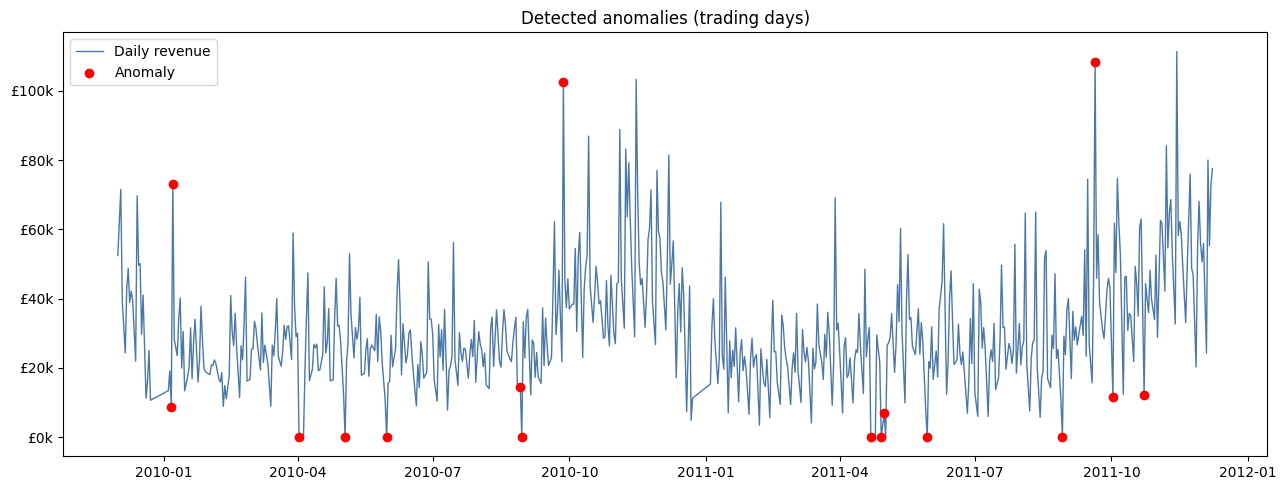

,Revenue,Typical,vs typical,Error
Date,,,,
2011-05-01,"6,814.11","9,834.75",0.69,4.61
2011-04-29,0.00,"26,138.69",0.00,0.92
2011-08-29,0.00,"28,451.76",0.00,0.88
2011-04-22,0.00,"26,138.69",0.00,0.67
2010-08-30,0.00,"28,038.38",0.00,0.64
2010-04-02,0.00,"21,279.39",0.00,0.64
2010-01-07,"73,020.89","30,099.53",2.43,0.61
2010-05-03,0.00,"26,750.15",0.00,0.59
2011-09-20,"108,364.34","44,360.78",2.44,0.57


In [69]:
recon = ae.predict([Xa, Xa[:, :, 1:]], verbose=0)[:, :, 0]
err   = np.abs(recon - Xa[:, :, 0])

err_sum, cnt = np.zeros(len(T)), np.zeros(len(T))
for i in range(len(Xa)):
    err_sum[i:i + W2] += err[i]
    cnt[i:i + W2] += 1
day_err = err_sum / cnt

threshold = np.percentile(day_err, 97.5)
anom = pd.DataFrame({"Revenue": trading.values, "Error": day_err}, index=trading.index)
anom["Typical"] = trading.groupby(trading.index.dayofweek).transform(
                      lambda s: s.rolling(9, center=True, min_periods=3).median()).values
anom["vs typical"] = (anom["Revenue"] / anom["Typical"]).round(2)
anom["Anomaly"] = anom["Error"] > threshold

print(f"Threshold: {threshold:.2f} | anomalies flagged: {anom['Anomaly'].sum()} of {len(anom)} trading days")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(anom.index, anom["Revenue"], color="#4c78a8", linewidth=1, label="Daily revenue")
flag = anom[anom["Anomaly"]]
ax.scatter(flag.index, flag["Revenue"], color="red", zorder=3, label="Anomaly")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.set_title("Detected anomalies (trading days)")
ax.legend(); plt.tight_layout(); plt.show()

flag.sort_values("Error", ascending=False).head(15)[["Revenue", "Typical", "vs typical", "Error"]]

**Observations: detected anomalies**
- The model flagged 16 of 615 trading days (the top 2.5% of reconstruction errors, threshold 0.47).
- Eight of the flagged days are weekdays with zero revenue that match UK bank holidays: Good Friday (2 April 2010, 22 April 2011), the May and spring bank holidays (3 and 31 May 2010, 30 May 2011), the summer bank holiday (30 August 2010, 29 August 2011) and the royal wedding holiday (29 April 2011). The model found these closures without being told about them.
- Three flagged days are large spikes, at 2.4 to 2.7 times the usual level for that weekday: £73k on 7 January 2010, £102k on 27 September 2010 and £108k on 20 September 2011. They are worth checking against large wholesale orders.
- Five flagged days are unusually weak, between 0.4 and 0.7 times the typical level, for example £6.8k on 1 May 2011 and £12.1k on 23 October 2011.
- Many alerts are explained by public holidays. In a production system a holiday calendar would label these days as expected, so analysts only see the unexplained spikes and drops.
- Anomaly detection here is unsupervised: there are no labelled "true" anomalies, so the check is whether the flags match known events, and most do.

## 18. Automated insight generator
The functions below turn the numbers into a written weekly report: revenue versus the previous week and last year, the best day, top product and country, anomalies, customers at risk, and the forecast. The same code can run for any week and feeds the app.

In [80]:
def build_report(asof):
    d = pd.Timedelta(days=1)
    start = asof - 6 * d
    wk   = daily.loc[start:asof]
    prev = daily.loc[start - 7 * d: asof - 7 * d]
    ly   = daily.loc[start - 364 * d: asof - 364 * d]
    s    = sales[(sales["Date"] >= start) & (sales["Date"] <= asof)]

    lines = []
    chg_prev = wk.sum() / prev.sum() - 1
    chg_ly   = wk.sum() / ly.sum() - 1
    lines.append(f"Revenue for {start:%d %b} to {asof:%d %b %Y} was £{wk.sum():,.0f}, "
                 f"{chg_prev:+.1%} versus the previous week and {chg_ly:+.1%} versus the same week last year.")

    orders = s["Invoice"].nunique()
    lines.append(f"There were {orders:,} orders with an average order value of £{wk.sum() / orders:,.0f}.")

    best = wk.idxmax()
    lines.append(f"The best day was {best:%A %d %b} with £{wk.max():,.0f}.")

    top_code = s.groupby("StockCode")["Revenue"].sum().idxmax()
    top_rev  = s.groupby("StockCode")["Revenue"].sum().max()
    lines.append(f"The top product was {prod.loc[top_code, 'Name'].title()} (£{top_rev:,.0f}).")
    exp = s[s["Country"] != "United Kingdom"].groupby("Country")["Revenue"].sum()
    if len(exp):
        lines.append(f"The strongest export market was {exp.idxmax()} (£{exp.max():,.0f}); "
                     f"exports were {exp.sum() / wk.sum():.0%} of the week's revenue.")

    recent = anom[anom["Anomaly"] & (anom.index > asof - 28 * d)]
    if len(recent):
        txt = "; ".join(f"{i:%d %b} (£{r:,.0f}, {v:.1f}x typical)" for i, r, v in
                         zip(recent.index, recent["Revenue"], recent["vs typical"]))
        lines.append(f"Unusual days in the last 28 days: {txt}.")
    else:
        lines.append("No unusual days were detected in the last 28 days.")

    big = now[(now["RiskBand"] == "High") & (now["Monetary"] >= now["Monetary"].quantile(0.8))]
    lines.append(f"{len(big):,} high-value customers (top 20% by spend) are rated high churn risk, "
                 f"with £{big['Monetary'].sum():,.0f} in lifetime spend.")

    f_tot, f_ly = forecast["Forecast"].sum(), forecast["LastYear"].sum()
    closed = int((forecast["Forecast"] == 0).sum())
    lines.append(f"The forecast for the next 28 days is £{f_tot:,.0f} ({f_tot / f_ly - 1:+.1%} versus the same period last year), "
                 f"with {closed} of the 28 days expected to have no sales (Saturdays and the Christmas closure). "
                 f"In a test on the previous Christmas period, this method was within about 5% of the actual total.")
    return lines
report = build_report(daily.index[-1])
print("\n".join("- " + l for l in report))

- Revenue for 02 Dec to 08 Dec 2011 was £365,791, +23.4% versus the previous week and +20.7% versus the same week last year.
- There were 651 orders with an average order value of £562.
- The best day was Monday 05 Dec with £80,011.
- The top product was Rabbit Night Light (£7,857).
- The strongest export market was Netherlands (£11,728); exports were 10% of the week's revenue.
- No unusual days were detected in the last 28 days.
- 59 high-value customers (top 20% by spend) are rated high churn risk, with £536,066 in lifetime spend.
- The forecast for the next 28 days is £478,169 (+5.1% versus the same period last year), with 13 of the 28 days expected to have no sales (Saturdays and the Christmas closure). In a test on the previous Christmas period, this method was within about 5% of the actual total.


## 19. Save the results for the app
The app does not need the 1M-row table. We save small summary tables (daily and monthly sales, products, countries, customer risk, forecast, anomalies, model results and the weekly report) and download them as one zip.

In [81]:
import os, shutil, json
from google.colab import files
from sklearn.metrics import roc_auc_score

OUT = "/content/app_data"
os.makedirs(OUT, exist_ok=True)

def put(table, name):
    table.to_csv(f"{OUT}/{name}.csv", index=False)
    print(f"saved {name}: {len(table):,} rows")

daily_tbl = (sales.groupby("Date")
                  .agg(Revenue=("Revenue", "sum"), Orders=("Invoice", "nunique"), Units=("Quantity", "sum"))
                  .reset_index())
daily_tbl = daily_tbl[daily_tbl["Date"] < "2011-12-09"]

monthly_tbl = (sales.groupby("YearMonth")
                    .agg(Revenue=("Revenue", "sum"), Orders=("Invoice", "nunique"), Units=("Quantity", "sum"))
                    .reset_index())
monthly_tbl["YearMonth"] = monthly_tbl["YearMonth"].astype(str)

country_tbl = sales.groupby(["YearMonth", "Country"])["Revenue"].sum().reset_index()
country_tbl["YearMonth"] = country_tbl["YearMonth"].astype(str)

dow_hour_tbl = sales.groupby(["DayName", "Hour"])["Revenue"].sum().reset_index()

customers_tbl = now.join(rfm[["R", "F", "M"]]).reset_index()
customers_tbl["RiskBand"] = customers_tbl["RiskBand"].astype(str)

put(daily_tbl, "daily_sales")
put(monthly_tbl, "monthly_sales")
put(country_tbl, "country_monthly")
put(dow_hour_tbl, "day_hour_sales")
put(prod.reset_index(), "products")
put(customers_tbl, "customers_rfm_churn")
put(seg.reset_index(), "segments_summary")
put(anom.rename_axis("Date").reset_index(), "anomalies")
put(forecast, "forecast_next28")
put(results2.rename_axis("Model").reset_index(), "forecast_model_comparison")
put(bt.reset_index(), "forecast_backtest")
put(imp.rename("Importance").rename_axis("Feature").reset_index(), "churn_feature_importance")
put(kpis, "kpis")
put(decision_log, "cleaning_log")

metrics = {"churn_auc_logistic": float(roc_auc_score(y_test, models["Logistic Regression"].predict_proba(X_test)[:, 1])),
           "churn_auc_forest": float(roc_auc_score(y_test, models["Random Forest"].predict_proba(X_test)[:, 1])),
           "churn_rate": float(feat["Churned"].mean()),
           "data_end": str(daily.index[-1].date()),
           "report": report}
json.dump(metrics, open(f"{OUT}/metrics_and_report.json", "w"), indent=2)

shutil.make_archive("/content/app_data", "zip", OUT)
files.download("/content/app_data.zip")

saved daily_sales: 603 rows
saved monthly_sales: 25 rows
saved country_monthly: 562 rows
saved day_hour_sales: 85 rows
saved products: 4,706 rows
saved customers_rfm_churn: 5,852 rows
saved segments_summary: 6 rows
saved anomalies: 615 rows
saved forecast_next28: 28 rows
saved forecast_model_comparison: 4 rows
saved forecast_backtest: 8 rows
saved churn_feature_importance: 9 rows
saved kpis: 7 rows
saved cleaning_log: 6 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20. Conclusions, limitations and next steps
**Findings**
- Revenue is strongly seasonal: it roughly doubles from summer to November, driven mainly by order volume, and growth year on year is modest (November 2011 was 1.7% above November 2010).
- Revenue depends on a few customers. The top 20% generate 76.8% of identified revenue, and the Champions segment (about 25% of customers) generates roughly 70%.
- Churn can be predicted from purchase history alone (ROC-AUC 0.80). Recency and order frequency are the main drivers, and 1,816 customers are rated high risk.
- For forecasting, the average of Holt-Winters and last year's pattern was best over eight 28-day windows (WAPE 29.6%, 28-day total typically within about 8%). For windows containing the Christmas closure, last year's pattern scaled by growth was used, because the other methods overshot by 33% to 70%. The LSTM underperformed on two years of data (WAPE 31.8%).
- The LSTM autoencoder flagged 16 unusual days, eight of which are UK bank holidays and three of which are large revenue spikes.
- Insight generation is automated: one function writes the weekly report from the model outputs.

**Limitations**
- Only two years of data, so each season is seen at most twice and the forecast cannot learn trends beyond that.
- 22.8% of the original rows have no Customer ID, so customer analysis covers about 77% of sales.
- The Christmas forecast rule is supported by a single test window.
- The data has no costs or margins, so the analysis covers revenue, not profit.

**Next steps**
- Add a UK holiday calendar so anomaly alerts exclude expected closures.
- Add more years of data and test further forecasting models.
- Schedule the weekly report to refresh automatically and add written commentary with a language model.